# Imports

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# This example imports functions from the DemoReadSGLXData module to read
# digital data. The metadata file must be present in the same directory as the binary file.
# Works with both imec and nidq digital channels.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter
from scipy import stats
from scipy.stats import linregress, spearmanr, kendalltau, pearsonr, circstd
from statsmodels.stats.multitest import multipletests
from pathlib import Path
from tkinter import Tk
from tkinter import filedialog
# from DemoReadSGLXData.readSGLX import readMeta, SampRate, makeMemMapRaw, ExtractDigital
from datetime import datetime
from scipy.io import savemat, loadmat
from sklearn.manifold import Isomap
import mat73, time, itertools
from ripser import ripser as tda
import matplotlib.gridspec as gridspec
from matplotlib_venn import venn2, venn3
import dill as pickle
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['font.sans-serif']=['Arial', 'Helvetica','Bitstream Vera Sans', 'DejaVu Sans', 'Lucida Grande', 
                                 'Verdana', 'Geneva', 'Lucid', 'Avant Garde', 'sans-serif']  

# for publication quality plots
def set_pub_plots(pal=sns.blend_palette(["gray","crimson", 'cyan', 'magenta', 'purple'  ],5)):
    sns.set_style("white")
    sns.set_palette('pastel')
    sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 2.5, "axes.linewidth":2.5, 'figure.facecolor': 'white'}) 
    sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
    # optional, makes markers bigger, too, axes.linewidth doesn't seem to work
    plt.rcParams['axes.linewidth'] = 2.5

rc_pub={'font.size': 25, 'axes.labelsize': 25, 'legend.fontsize': 25.0, 
    'axes.titlesize': 25, 'xtick.labelsize': 25, 'ytick.labelsize': 25, 
    #'axes.color_cycle':pal, # image.cmap - rewritesd the default colormap
    'axes.linewidth':2.5, 'lines.linewidth': 2.5,
    'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black','axes.labelcolor':'black','text.color':'black'}
# to restore the defaults, call plt.rcdefaults() 

#set_pub_bargraphs()
set_pub_plots()
sns.set_context('poster')
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False


# % 1 = position
# % 2 = linear velocity
# % 3 = Angular velocity
# % 4 = HD
# % 5 = theta phase
# % 8 = HD + postion
# % 11 = HD + linear velocity
# % 13 = HD + angular velocity
# % 15 = HD + theta phase
# % 17 = HD + position + linear velocity
# % 19 = HD + position + angular velocity
# % 21 = HD + position + theta phase
# % 22 = HD + Linear velocity + angular velocty
# % 24 = HD + Linear velocity + theta phase
# % 25 = HD + Angular velocity + theta phase
# % 26 = HD + Position + Linear velocity + Angular velocity
# % 28 = HD + Position + Linear velocity + Theta Phase
# % 29 = HD + Position + Angular velocity + Theta Phase
# % 30 = HD + Linear Velocity + Angular velocity + Theta Phase
# % 31 = HD + Position + Linear Velocity +Angular velocity + Theta Phase

# Functions

In [1]:
def bin_smooth_spk(df, binSize):
    binSize = 0.02
    trace_length = round(df.spk.max())
    boxcar = np.ones(int(1/binSize))
    edges = np.arange(0, trace_length, binSize)
    ls_df = [] 
    for unit in df.cid.unique():
        spkt = df[df.cid == unit].spk
        hist, bins = np.histogram(spkt, bins = edges)
        spkd = np.convolve(hist, boxcar, mode = 'same')
        df_tmp = pd.DataFrame({'cid': unit, 'hz': spkd, 'times': bins[:-1]})
        ls_df.append(df_tmp)
    #     print(spkt)
    df_out = pd.concat(ls_df)
    return df_out

In [2]:
def adjust_offset_emb(y, dec):
    yerr = ((y[:] - dec[:]) + 180)%360 - 180
    offset = np.mean((yerr))
    # adjust offset
    dec = (dec + offset) % 360 
    return dec

def decode_az_isomap(x, y, yaw):
    dec_err = 0
    yaw_dec = 0
    yaw_dec_xy = np.arctan2(x, y)*180/np.pi
    yaw_dec_yx = np.arctan2(y, x)*180/np.pi
        
    yaw_dec_xy1 = yaw_dec_xy + 180
    yaw_dec_yx1 = yaw_dec_yx + 180
    
    yaw_dec_xy2 = yaw_dec_xy
    yaw_dec_xy2[yaw_dec_xy2 < 0] = yaw_dec_xy2[yaw_dec_xy2 < 0] + 360
    
    yaw_dec_yx2 = yaw_dec_yx
    yaw_dec_yx2[yaw_dec_yx2 < 0] = yaw_dec_yx2[yaw_dec_yx2 < 0] + 360
    
    yaw_dec_xy1 = adjust_offset_emb(yaw, yaw_dec_xy1)
    yaw_dec_xy2 = adjust_offset_emb(yaw, yaw_dec_xy2)
    yaw_dec_yx1 = adjust_offset_emb(yaw, yaw_dec_yx1)
    yaw_dec_yx2 = adjust_offset_emb(yaw, yaw_dec_yx2)
    
    dec_err1 = np.mean(abs(((yaw[:] - yaw_dec_xy1[:]) + 180)%360 - 180))
    dec_err2 = np.mean(abs(((yaw[:] - yaw_dec_xy2[:]) + 180)%360 - 180))
    dec_err3 = np.mean(abs(((yaw[:] - yaw_dec_yx1[:]) + 180)%360 - 180))
    dec_err4 = np.mean(abs(((yaw[:] - yaw_dec_yx2[:]) + 180)%360 - 180))
    
    dec_arr = np.array((dec_err1, dec_err2, dec_err3, dec_err4))
    idx = dec_arr.argmin()
    if idx == 0:
        yaw_dec = yaw_dec_xy1
    elif idx == 1:
        yaw_dec = yaw_dec_xy2
    elif idx == 2:
        yaw_dec = yaw_dec_yx1
    elif idx == 3:
        yaw_dec = yaw_dec_yx2
        
    return yaw_dec, dec_arr[idx], idx

In [3]:
def get_stat_run_epochs(speed, window_size = 25, speed_thr = 4):
    speed = abs(speed)
    speed = speed[:speed.size//window_size*window_size]
    speed_bin_mean = np.nanmean(speed.reshape(-1, window_size), 1)  
    speed_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] > speed_thr])[:]
    stat_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] <= speed_thr])[:]
    return stat_idx, speed_idx


In [4]:
def get_shank_from_ch(ch, probe_conf):
    sh = -1
    if ch in d_probe_conf[probe_conf]['shank0']:
        sh = 0
    elif ch in d_probe_conf[probe_conf]['shank1']:
        sh = 1
    elif ch in d_probe_conf[probe_conf]['shank2']:
        sh = 2
    elif ch in d_probe_conf[probe_conf]['shank3']:
        sh = 3
    return sh

In [5]:
def consecutive(data, stepsize=1):
    return np.split(data, np.where(np.diff(data) != stepsize)[0]+1)

a = np.array([0, 47, 48, 49, 50, 97, 98, 99])
b = consecutive(a)

def ang_diff(a1, a2):
    a1 = np.array(a1)
    a2 = np.array(a2)
    return 180 - abs(abs(a1 - a2) - 180)

ang_diff(300, 45)


105

In [6]:
# def get_long_bettibars(h0, h1, h2):
#     h0[~np.isfinite(h0)] = 60
#     plot_prcnt = [95, 50, 50] # order is h0, h1, h2
#     to_plot = []
#     for curr_h, cutoff in zip([h0, h1, h2], plot_prcnt):
# #         print(curr_h.shape)
#         if curr_h.shape[0] < 100:
#             plot_h = curr_h
#         else:
#             bar_lens = curr_h[:,1] - curr_h[:,0]
#             plot_h = curr_h[bar_lens > np.percentile(bar_lens, cutoff)]
#         if cutoff == plot_prcnt[1]: 
#             long_bar = sorted(plot_h[:, 1] - plot_h[:, 0])[-1]
#         #         print(long_bar)
#         to_plot.append(plot_h)
        
#     return to_plot, long_bar

def compute_dYaw(yaw):

    dYaw = np.gradient(yaw)            
    idx_pos = np.where((dYaw > 180))[0]
    idx_neg = np.where((dYaw < -180))[0]

    dYaw[idx_pos] = dYaw[idx_pos] - 360
    dYaw[idx_neg] = dYaw[idx_neg] + 360
    
#     deltaYaw_filt = savgol_filter(dYaw, window_length=11, polyorder=2)
    # max 250 deg/s
    dYaw[abs(dYaw) > 5] = 0

    return dYaw

def compute_ringness(inp):
 
    dist_tmp = []
    vis_dist = []
    x = inp[:,0]
    y = inp[:,1]
    n_samples10 = x.size//4
    centroid = np.mean(inp, axis = 0)
    
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    for idx in range(inp.shape[0]):
#         dist_tmp.append(math.dist(centroid[:],data[idx,:]))
        dist_tmp.append(np.linalg.norm(centroid-inp[idx, :])) 
        vis_dist.append(np.linalg.norm(viscenter-inp[idx, :]))
        
#     dist_tmp.sort(reverse = True)
    vis_dist_out = vis_dist.copy()
    vis_dist.sort()
    bot10 = vis_dist[:n_samples10]
    vis_dist.sort(reverse = True)
    top10 = vis_dist[:n_samples10]
    
    radius = np.mean(dist_tmp[:])
#     vis_radius = np.mean(vis_dist[:])
    ringness = np.mean(bot10)/np.mean(top10)*radius
#     for idx in range(data.shape[0]):
#         ringness.append(np.abs(np.sqrt((data[idx,0]-centroid[0])**2+(data[idx,1]-centroid[1])**2)-radius))
    
    return radius, centroid, ringness, vis_dist_out

def compute_radius_runmask(x, y, run_mask):
    # Instead of true min/max, use robust extremes
    cx = (np.percentile(x[run_mask], 2) + np.percentile(x[run_mask], 98)) / 2
    cy = (np.percentile(y[run_mask], 2) + np.percentile(y[run_mask], 98)) / 2
    
    # Apply to all epochs
    radius = np.sqrt((x[:] - cx)**2 + (y[:] - cy)**2)
    return (cx,cy), radius

def compute_radius_old (x, y):
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    vis_r = np.sqrt((x - viscenter[0])**2 + (y - viscenter[1])**2)
    r = np.sqrt(x**2 + y**2)
    return r, vis_r

In [7]:
def compute_betti(isomap_emb):
    H1_rates = isomap_emb
    barcodes = tda(H1_rates, maxdim=1, coeff=2)['dgms']
    h0 = barcodes[0]
    h1 = barcodes[1]

    # H2. Need to subsample points for computational tractability if 
    # number of points is large (can go higher but very slow)
    if len(H1_rates) > 1500:
        idx = np.random.choice(np.arange(len(H1_rates)), 1500, replace=False)
        H2_rates = H1_rates[idx]
    else:
        H2_rates = H1_rates
    barcodes = tda(H2_rates, maxdim=2, coeff=2)['dgms']
    h2 = barcodes[2]
    return h0, h1, h2

def get_long_bettibars(h0, h1, h2):
    h0[~np.isfinite(h0)] = 60
    plot_prcnt = [95, 90, 50] # order is h0, h1, h2
    to_plot = []
    for curr_h, cutoff in zip([h0, h1, h2], plot_prcnt):
#         print(curr_h.shape)
        top_indices  = np.argsort(curr_h[:, 1] - curr_h[:, 0])[-20:]
#         if curr_h.shape[0] < 100:
        plot_h = curr_h
#         else:
#             bar_lens = curr_h[:,1] - curr_h[:,0]
#             plot_h = curr_h[bar_lens > np.percentile(bar_lens, cutoff)]
        if cutoff == plot_prcnt[1]: 
            long_bar = sorted(curr_h[:, 1] - curr_h[:, 0])[-2:]
        to_plot.append(curr_h[top_indices])
        
    return to_plot, long_bar

In [9]:
# both arena and hr present
good_sess = ['JA0144_20211212',  'JA0153_20220209', 'JA0162_20220302', 'JA0164_20220419',
             'JA0178_20220819', 'JA0181_20220812', 'JA0181_20220815', 'JA0181_20220818',
             'MC022_20220712', 'JA0153_20220126' ]

# Load processed data

In [21]:
del d_hr_data

In [22]:
path = r"C:\Users\01\Documents\d_rl-hfix_public.p"
d_hr_data = pd.read_pickle(path)
d_hr_data.keys()

dict_keys(['20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA0181_darkHR1', '20220712_MC022_dark1', '20220712_MC022_darkHR1'])

In [11]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\d_hr_emb5.p"
# with open(path, 'rb') as handle:
#     d_hr_emb = pickle.load(handle)
d_hr_emb = pd.read_pickle(path)
d_hr_emb.keys()

dict_keys(['20211207_JA0144_light1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220906_JA0178_light1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA

In [12]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\df_hr_betti5.pkl"
df_hr_betti = pd.read_pickle(path)
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [13]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\df_hrtun_run5.pkl"
df_hrtun_run = pd.read_pickle(path)
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1


In [15]:
# def save_subset(dictionary, keys):
#     """Extract subset of dictionary using comprehension."""
#     return {key: dictionary[key] for key in keys if key in dictionary}


# subset = save_subset(d_hr_data, rec_id_keep)
# print(subset.keys())  # {'a': 1, 'c': 3, 'e': 5}

{'a': 1, 'c': 3, 'e': 5}


In [14]:
rec_id_keep = ['20220126_JA0153_light1', '20220126_JA0153_lightHR1',
       '20220302_JA0162_light1', '20220302_JA0162_lightHR1',
       '20220419_JA0164_light1', '20220419_JA0164_lightHR1',
       '20220819_JA0178_light1', '20220819_JA0178_lightHR1',
       '20220822_JA0178_light1', '20220822_JA0178_lightHR1',
       '20220812_JA0181_light1', '20220812_JA0181_lightHR1',
       '20220815_JA0181_light1', '20220815_JA0181_lightHR1',
       '20220818_JA0181_light1', '20220818_JA0181_lightHR1',
       '20220712_MC022_light1', '20220712_MC022_lightHR1', 
        '20220126_JA0153_dark1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_dark1', '20220302_JA0162_darkHR1',
       '20220419_JA0164_dark1', '20220419_JA0164_darkHR1',
       '20220822_JA0178_dark1', '20220822_JA0178_darkHR1',
       '20220906_JA0178_dark1', '20220906_JA0178_darkHR1',
       '20220812_JA0181_dark1', '20220812_JA0181_darkHR1',
       '20220815_JA0181_dark1', '20220815_JA0181_darkHR1',
       '20220818_JA0181_dark1', '20220818_JA0181_darkHR1',
       '20220712_MC022_dark1', '20220712_MC022_darkHR1']

In [20]:
# with open('d_rl-hfix_public.p', 'wb') as handle:
#     pickle.dump(subset, handle, protocol=pickle.HIGHEST_PROTOCOL)

# Off-manifold dynamics

In [24]:
from pathlib import Path

# Check if directory exists
save_dir = Path(r"C:\Users\01\Documents")


In [25]:
# df_hr_tuning.to_pickle('df_hr_tuning_master.pkl')

In [26]:
# both arena and hr present
good_sess = ['JA0144_20211212',  'JA0153_20220209', 'JA0162_20220302', 'JA0164_20220419',
             'JA0178_20220819', 'JA0181_20220812', 'JA0181_20220815', 'JA0181_20220818',
             'MC022_20220712', 'JA0153_20220126' ]

In [27]:
def circ_preferred_direction(tuning_curve, bin_centers_rad, method="circular_mean"):
    """
    Estimate the preferred direction of one HD cell.

    Parameters
    ----------
    tuning_curve   : 1-D array, firing rate per angular bin
    bin_centers_deg: 1-D array, centre of each bin (degrees)
    method         : 'circular_mean' (default) or 'peak'

    Returns
    -------
    pref_dir : float, degrees [0, 360)
    """
    if method == "peak":
        pk, _ = find_peaks(tuning_curve)
        if len(pk) == 0:
            pk = [np.argmax(tuning_curve)]
        best = pk[np.argmax(tuning_curve[pk])]
        return float(bin_centers_deg[best]) % 360
    else:  # circular_mean — robust to noise
        angles = np.deg2rad(bin_centers_rad)
        # angles = bin_centers_rad
        weights = np.clip(tuning_curve, 0, None)
        weights /= weights.sum() + 1e-12
        mean_angle = np.arctan2(
            np.sum(weights * np.sin(angles)),
            np.sum(weights * np.cos(angles))
        )
        return float(np.rad2deg(mean_angle) % 360)

In [28]:
ls_pref = []
for k in d_hr_data.keys():
    tmp_df = d_hr_data[k]['tuning']
    _inp = tmp_df[(tmp_df.rec_id == k) & (tmp_df.hdc_flag == True)]
    idx = _inp.groupby([ 'rec_id', 'cuid'])['tuning'].transform(lambda x: x.max()) == _inp['tuning']
    tmp_df_pref = _inp[idx][['condition', 'rec_id', 'cids', 'x_tuning', 'tuning']]
    ls_pref.append(tmp_df_pref)
    # break
df_pref = pd.concat(ls_pref)
df_pref.head()

,condition,rec_id,cids,x_tuning,tuning
8,light1,20220126_JA0153_light1,61.0,160.0,11.956379
11,light1,20220126_JA0153_light1,150.0,220.0,11.109994
11,light1,20220126_JA0153_light1,155.0,220.0,51.626466
8,light1,20220126_JA0153_light1,156.0,160.0,38.695885
11,light1,20220126_JA0153_light1,161.0,220.0,38.171971


In [29]:
d_hr_data.keys()

dict_keys(['20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA0181_darkHR1', '20220712_MC022_dark1', '20220712_MC022_darkHR1'])

In [30]:
d_hr_emb.keys()

dict_keys(['20211207_JA0144_light1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220906_JA0178_light1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA

20220126_JA0153_lightHR1
circstd is too high 13.696211418436045
20220126_JA0153_lightHR1, ep idx: 29
len 190, mean: 60.89503597140978 std: 1.16, idx: 1345 - 1535
(3, 190) (16, 190)
pear r HDC@pref 0.5163314079133094 HDC @ non-pref -0.7099772236821018
rand pref HDC -0.33070644839498325

circstd is too high 14.91046135381278
20220126_JA0153_lightHR1, ep idx: 39
len 35, mean: 354.61787624603215 std: 3.07, idx: 1790 - 1825
not enough pref HDC 0
20220126_JA0153_lightHR1, ep idx: 41
len 215, mean: 197.16657988751183 std: 0.95, idx: 1875 - 2075
(10, 200) (9, 200)
pear r HDC@pref 0.3919105762355939 HDC @ non-pref -0.01895979770739878
rand pref HDC 0.10403240878687439

20220126_JA0153_lightHR1, ep idx: 50
len 190, mean: 103.89353676440189 std: 3.97, idx: 2450 - 2640
(4, 190) (15, 190)
pear r HDC@pref 0.5347113377336474 HDC @ non-pref -0.5598400347005317
rand pref HDC -0.10354932023177806

circstd is too high 17.415824392252837
20220126_JA0153_lightHR1, ep idx: 67
len 45, mean: 160.7289694380348

C:\Users\01\AppData\Local\Temp\ipykernel_17860\861487649.py:185: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  f, ax = plt.subplots(4, figsize = (10, 12), sharex = 'col')


rand pref HDC -0.15926409059495522

20220302_JA0162_lightHR1, ep idx: 87
len 160, mean: 222.15304314578427 std: 3.9, idx: 3655 - 3815
not enough pref HDC 1
20220302_JA0162_lightHR1, ep idx: 88
len 155, mean: 48.71261277875497 std: 3.06, idx: 3825 - 3980
not enough pref HDC 1
20220302_JA0162_lightHR1, ep idx: 89
len 40, mean: 14.132590261339468 std: 2.78, idx: 3990 - 4030
not enough pref HDC 0
20220302_JA0162_lightHR1, ep idx: 91
len 660, mean: 28.762708174732538 std: 1.77, idx: 4140 - 4340
not enough pref HDC 1
20220419_JA0164_lightHR1
circstd is too high 20.574688691474588
20220419_JA0164_lightHR1, ep idx: 2
len 150, mean: 97.45691038234136 std: 2.44, idx: 210 - 360
not enough pref HDC 0
20220419_JA0164_lightHR1, ep idx: 13
len 3845, mean: 79.40206968819368 std: 3.23, idx: 740 - 940
(3, 200) (7, 200)
pear r HDC@pref 0.9233309283702694 HDC @ non-pref 0.11839465231149852
rand pref HDC 0.4123794995905784

20220819_JA0178_lightHR1
20220819_JA0178_lightHR1, ep idx: 14
len 855, mean: 48.714

,dts,animal_name,cond,rec_id,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,29,0.516331,-0.709977,0.224094,True,0.118377
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,41,0.391911,-0.018960,-0.231367,True,0.041279
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,50,0.534711,-0.559840,-0.189930,True,0.157587
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,67,0.645021,0.334978,0.325120,True,0.396868
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,74,0.802182,-0.674151,-0.145394,True,0.031821


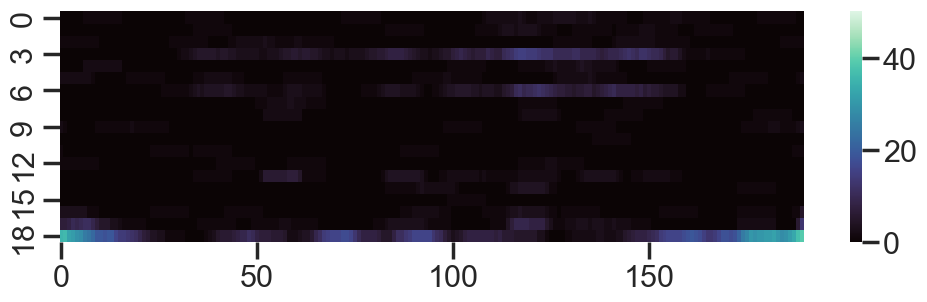

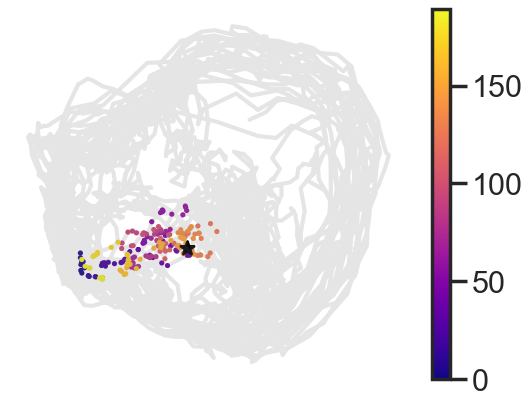

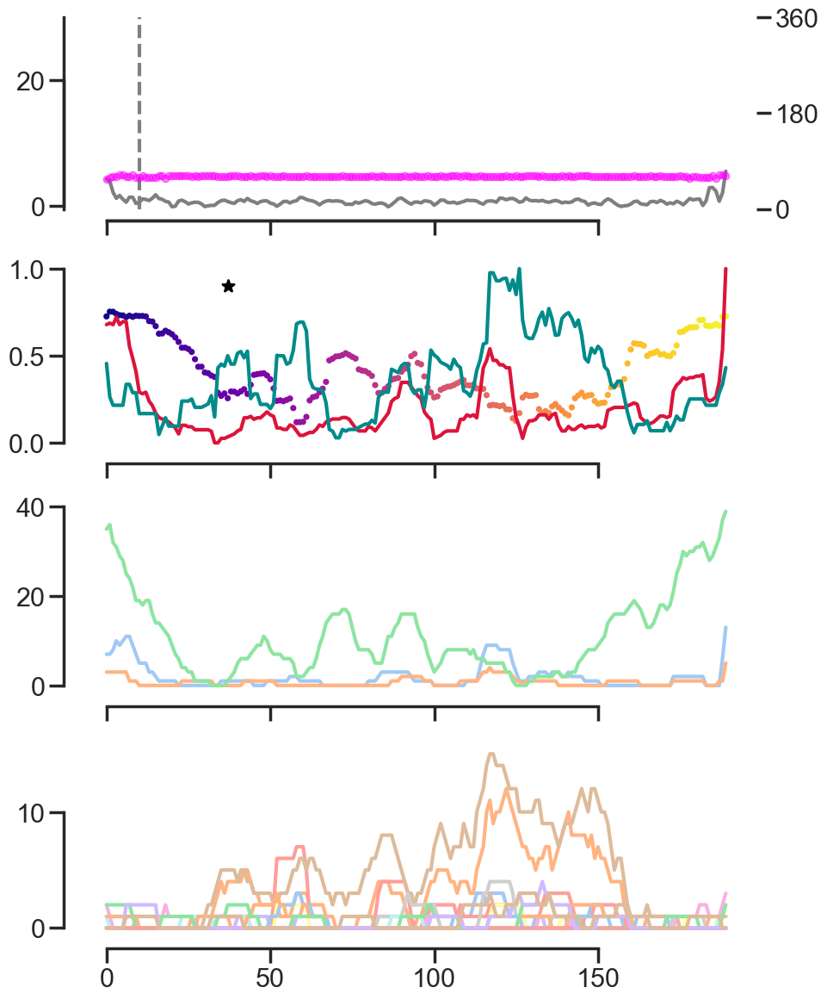

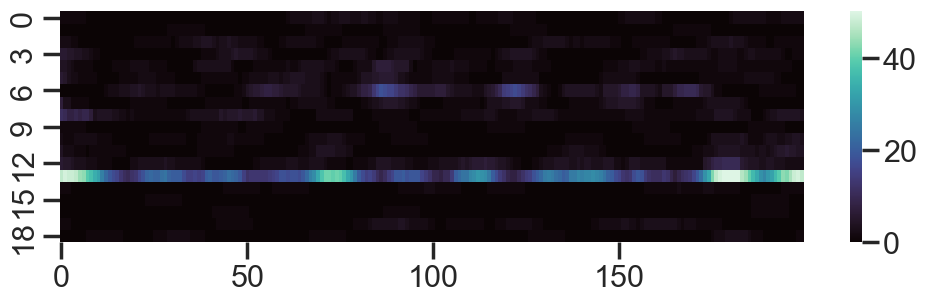

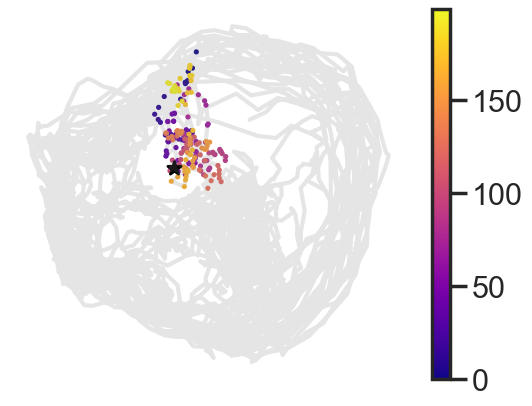

...

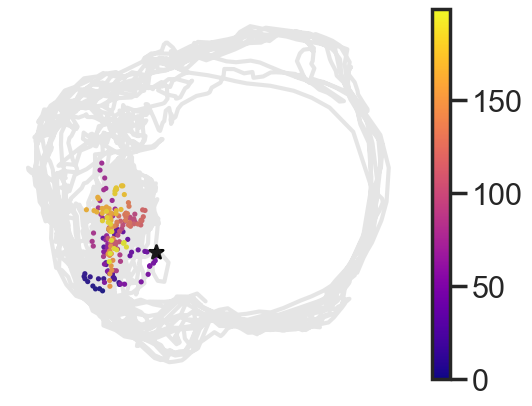

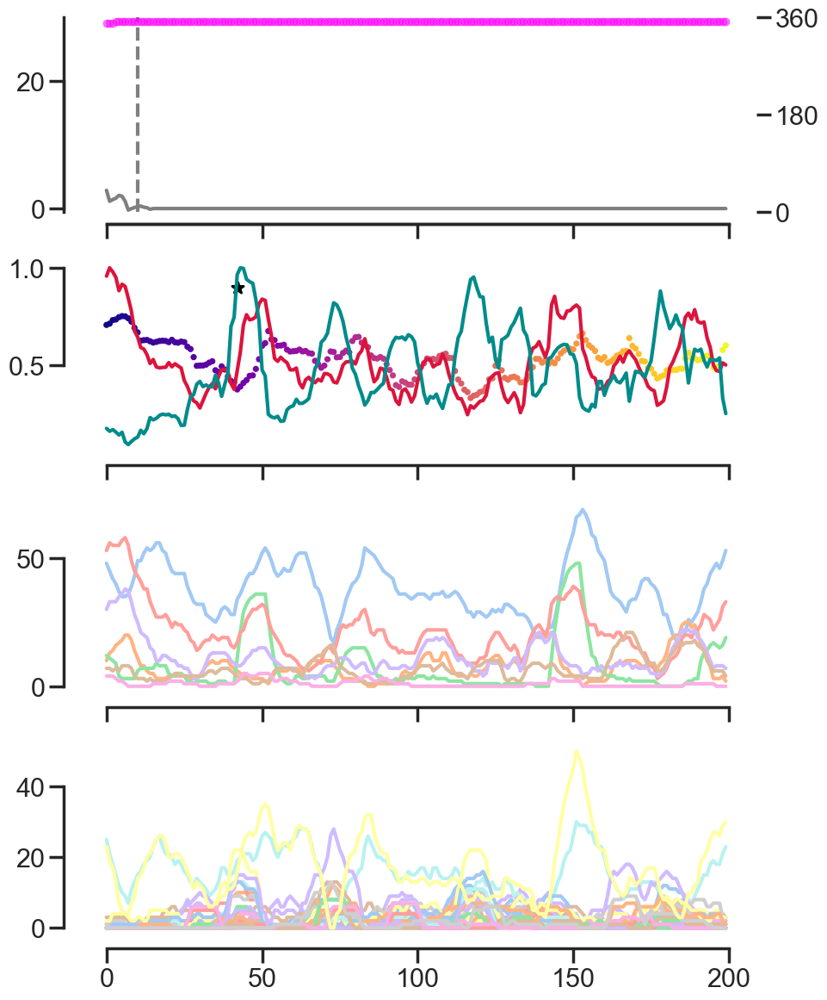

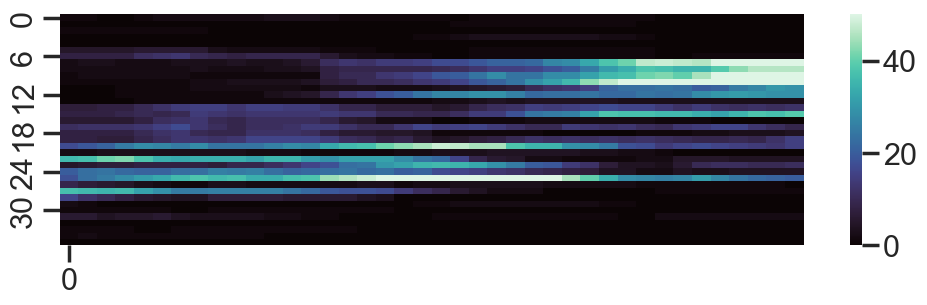

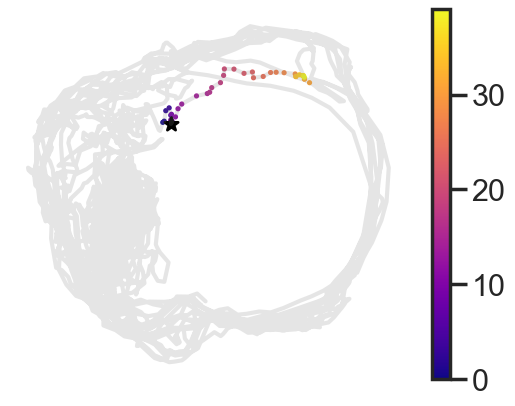

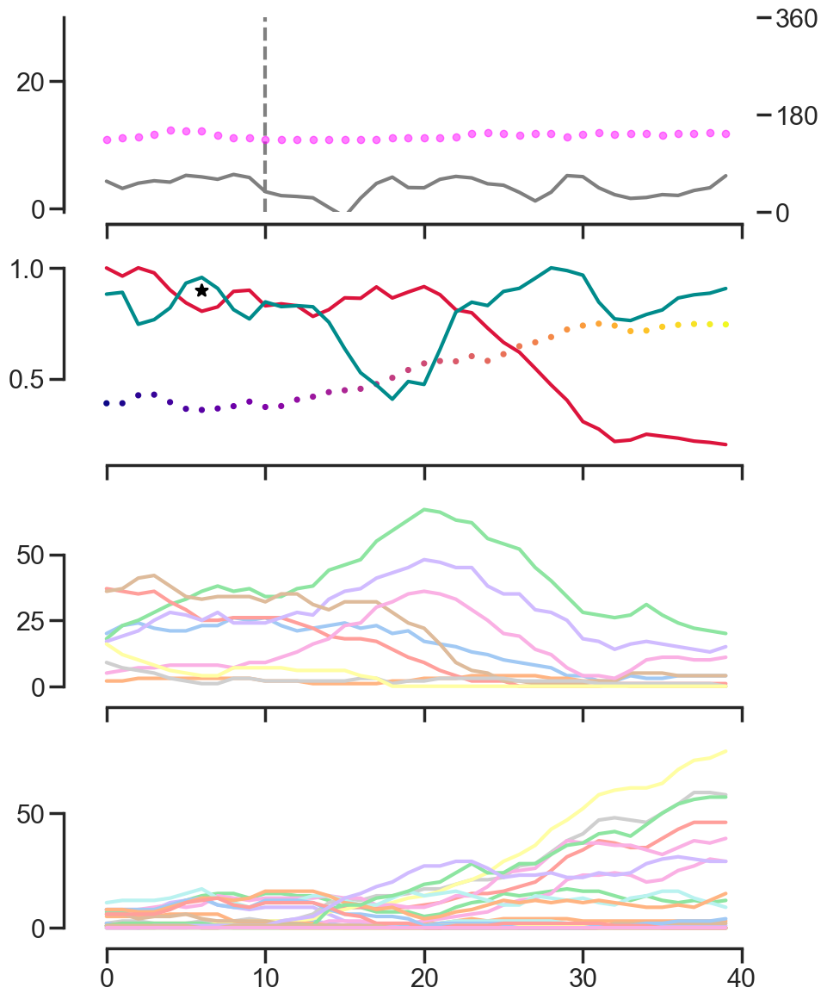

In [33]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
ep_idx = 0
ep_offset = 10
to_plot = True
# 1-10s
ep_min_dur, ep_max_dur = 30, 200
pref_dir_thr = 45

for k in d_hr_emb.keys():
    if 'HR1' not in k:
        continue

    # if '20220712_MC022_lightHR1' not in k:
    #     continue
        
    print(k)
    try:
        tmp_ephys = d_hr_data[k]['ephys']
        tmp_beh = d_hr_data[k]['beh']
    except:
        print('no rec found')
        continue
    dts, animal_name, cond = k.split('_')[-3:]
#     sess_hdc = tmp_ephys[tmp_ephys.hdc_flag == True].cids.unique()
    sess_hdc = df_pref[df_pref.rec_id == k].cids.unique()
    if sess_hdc.size < 8:
        print(f'not enough HDC {sess_hdc.size}')
        continue



#     sh = d_good_shanks[implant]
#     tmp_hist = df_hist_master[(df_hist_master.mouse_id == mouse_id) 
#            & (df_hist_master.dts == dts)
#            & (df_hist_master.group != 'noise')
#           & (df_hist_master.shank.isin(sh))]
#     units_in = tmp_hist.id.unique()
#     sess_hdc = tmp_hist[tmp_hist.hdc == 1].id.values
#     print(tmp.rec_id.values[0])
    
    measured_yaw = tmp_beh['yaw'].values[::5]
    if np.min(measured_yaw) < -10:
        measured_yaw = measured_yaw + 180
    lin_speed = tmp_beh['lin_vel'].values[::5]
    
    emb_x, emb_y = d_hr_emb[k]['isomap'][:,0], d_hr_emb[k]['isomap'][:,1]
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
    # get stat epochs
    stat_epoch = consecutive(stat_idx)

    # compute off manifold ratios
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius_runmask(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()

    # find hdc ids for this rec
    hdc_units = df_pref[df_pref.rec_id == k].cids.values
    pref_dir = df_pref[df_pref.rec_id == k].x_tuning.values
    sorted_pref_dir = np.argsort(pref_dir)
    tmp_ephys_sel = tmp_ephys[tmp_ephys.cids.isin(sess_hdc)]
    offman_ep_flag = False
    
    for ep_idx, ep in enumerate(stat_epoch):
        # if ep_idx != 32:
        #     continue
        # at least 1s and no change in az
        if (len(ep) > ep_min_dur):
            start, end = ep[0], ep[:][-1]+1
            if start < 0:
                start = 0
            if ep.size > ep_max_dur:
                end = start + ep_max_dur
                
            this_man_rad = rad_manifold_norm[start:end]
            if this_man_rad.max() - this_man_rad.min() > 0.2:
                offman_ep_flag = True
            else:
                continue

                
            angles = np.deg2rad(measured_yaw[start:end])
            circstd = stats.circstd(angles[ep_offset:])
            circstd = np.rad2deg(circstd)
            # during stat
            this_yaw = np.rad2deg(stats.circmean(angles[ep_offset:]))
            if circstd > 5:
                print(f'circstd is too high {circstd}')
                continue
            
            print(f'{k}, ep idx: {ep_idx}')
            print(f'len {len(ep)}, mean: {this_yaw} std: {round(circstd, 2)}, idx: {start} - {end}')
            
            # get hdc preferring this yaw
            pref_idx = ang_diff(pref_dir, this_yaw) <= pref_dir_thr
            non_pref_idx = ang_diff(pref_dir, this_yaw) > pref_dir_thr 
            if sum(pref_idx) < 3:
                print(f'not enough pref HDC {sum(pref_idx)}')
                continue
    
            _inp = tmp_ephys_sel.pivot(index = 'cids', columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_hdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_nonhdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[non_pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]

#             to calculate corrs
            _inp_norm = _inp[:, :]/(_inp.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_hdc_norm = _inp_hdc[:, :]/(_inp_hdc.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_nonhdc_norm = _inp_nonhdc[:, :]/(_inp_nonhdc.max(axis = 1) + 1e-9)[:,np.newaxis]

            # min in first 5s after run
            offset = this_man_rad[:50].argmin()
            print(_inp_hdc.shape, _inp_nonhdc_norm.shape)
            hdc_vec = _inp_hdc_norm.sum(axis = 0)
            hdc_gain = hdc_vec/hdc_vec.max()
            nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
            nonhdc_gain = nonhdc_vec/nonhdc_vec.max()
            
            r_hdc, pval = (stats.pearsonr(this_man_rad, hdc_gain))
            r_nonhdc, pval = (stats.pearsonr(this_man_rad, nonhdc_gain))
            print(f'pear r HDC@pref {r_hdc} HDC @ non-pref {r_nonhdc}')
            
            # shuffled population
            ls_rand = []
            for i in range(20):
                rand_n = np.random.randint(3, hdc_units.size//2)
                rand_units = np.random.choice(hdc_units, size = rand_n)
                _inp_rand = tmp_ephys_sel[tmp_ephys_sel.cids.isin(rand_units)].pivot(index = 'cids', 
                                                             columns = 'times', values = 'hz').values[:, ::5][:, start:end]
                _inp_rand_norm = _inp_rand[:, :]/(_inp_rand.max(axis = 1) + 1e-9)[:,np.newaxis]
                
                if np.sum(_inp_rand_norm) < 1:
                    continue
                rand_vec = _inp_rand_norm.sum(axis = 0)
                rand_gain = rand_vec/rand_vec.max()
                r_rand, pval = stats.pearsonr(this_man_rad, rand_gain)
                ls_rand.append(r_rand)
            print(f'rand pref HDC {np.mean(ls_rand)}')
            print()

            if to_plot:
                # to plot
                # _inp_norm = _inp[:, start:end]/_inp.max(axis = 1)[:,np.newaxis]
                # _inp_hdc_norm = _inp_hdc[:, start:end]/_inp_hdc.max(axis = 1)[:,np.newaxis]
                # _inp_nonhdc_norm = _inp_nonhdc[:, start:end]/_inp_nonhdc.max(axis = 1)[:,np.newaxis]
                # hdc_vec = _inp_hdc_norm.sum(axis = 0)
                # hdc_gain = hdc_vec/hdc_vec.max()
                # nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
                # nonhdc_gain = nonhdc_vec/nonhdc_vec.max()

                f, ax = plt.subplots(1, figsize = (12, 3))
                sns.heatmap(_inp[(sorted_pref_dir[::-1])], cmap = 'mako', xticklabels=50, vmax = 50)
                # ax_1 = ax.twinx()
                # ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 1)
                # ax_1.set_yticks([0, 15, 30])
                # ax_2 = ax.twinx()
                # ax_2.plot( measured_yaw[start:end],  color = 'magenta', label = 'yaw', alpha = 0.75)
                # ax_2.set_yticks([0, 180, 360])
                
                # filepath = save_dir / f'hr_heatmap_hdc_{k}_{ep_idx}_.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = emb_x[start:end], emb_y[start:end]
                plt.plot(emb_x, emb_y, c = 'gray', alpha = 0.2)
    #             plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 10,  c = x_time, cmap = 'afmhot', vmax = 400)
    #             plt.colorbar()
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:], 
                            cmap = 'plasma')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(emb_x[start + offset], emb_y[start + offset], c = 'k', s = 100, marker = "*")
                plt.axis('off')
#                 plt.show()

                # filepath = save_dir / f'scatter_isomap-traj_{k}_{ep_idx}.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots(4, figsize = (10, 12), sharex = 'col')
                x_time = np.arange(0, end - start)
    #             sorted_idx = np.argsort(pref_dir[pref_idx])
    #             sns.heatmap(_inp_hdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 1, ax  = ax[1], cbar = False
    # #                         cbar_kws = dict(use_gridspec=False, location = "top")
    #                        )
    #             sorted_idx = np.argsort(pref_dir[non_pref_idx])
    #             sns.heatmap(_inp_nonhdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 0.5, ax  = ax[2], cbar = False)
                
                for i in range(_inp_hdc.shape[0]):
                    ax[2].plot(_inp_hdc[i, :])
            
                for i in range(_inp_nonhdc.shape[0]):
                    ax[3].plot(_inp_nonhdc[i, :])
           
                ax[1].scatter( x_time, this_man_rad, s = 10, label = 'iso rad',  
                              c = x_time, cmap = 'plasma')
                ax[1].plot( hdc_gain, label = 'hdc gain', c = 'crimson')
                ax[1].plot( nonhdc_gain, label = 'non-hdc gain', c = 'darkcyan')
                ax[1].scatter(x = offset, y = 0.9, c = 'k', s = 100, marker = "*")

                ax[0].plot( lin_speed[start:end],  color = 'k', label = 'lin speed', alpha = 0.5)
                ax[0].axvline(x = ep_offset, c = 'gray', ls = '--')
                ax[0].set_ylim(-0.5, 30)
                ax_2 = ax[0].twinx()
                ax_2.plot( measured_yaw[start:end], '.', color = 'magenta', label = 'yaw', alpha = 0.5)
                ax_2.set_yticks([0, 180, 360])

    #             f.legend(loc='outside upper right')
                f.tight_layout()
                sns.despine(offset = 10, trim = True)
                # plt.show()
                # break
                # time.sleep(0.2)
                
                # filepath = save_dir / f'hr_line-hdcgain-{k}_{ep_idx}.pdf'
                # plt.savefig(filepath, transparent = True)

            df_tmp = pd.DataFrame({ 
            'dts': dts, 'animal_name': animal_name, 'cond': cond, 'rec_id':k,'ep_idx': ep_idx,
#             'rad_manifold_ep':rad_manifold_norm[ep], 'hdc_pop': hdc_vec[ep_offset:], 'nonhdc_pop': nonhdc_vec[ep_offset:],
            'r_hdc': r_hdc, 'r_nonhdc': r_nonhdc, 'r_rand': r_rand, 
                'offman_ep_flag': offman_ep_flag, 'min_rad' :rad_manifold_norm[ep].min() 
#                 'emb_x':emb_x[ep] , 'emb_y':emb_y[ep],  'ep': ep, 
                              }, index = [0])
            ls_df.append(df_tmp)
              

    # break
df_hr_mandyn = pd.concat(ls_df)
df_hr_mandyn.head()

In [34]:
df_hr_mandyn.groupby('rec_id').count()

,dts,animal_name,cond,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
rec_id,,,,,,,,,
20220126_JA0153_darkHR1,4,4,4,4,4,4,4,4,4
20220126_JA0153_lightHR1,6,6,6,6,6,6,6,6,6
20220302_JA0162_lightHR1,2,2,2,2,2,2,2,2,2
20220419_JA0164_lightHR1,1,1,1,1,1,1,1,1,1
20220712_MC022_darkHR1,3,3,3,3,3,3,3,3,3
20220712_MC022_lightHR1,6,6,6,6,6,6,6,6,6
20220812_JA0181_darkHR1,1,1,1,1,1,1,1,1,1
20220812_JA0181_lightHR1,2,2,2,2,2,2,2,2,2
20220815_JA0181_lightHR1,5,5,5,5,5,5,5,5,5


In [510]:
# pd.DataFrame({'yaw': measured_yaw[start:end], 'lin_velocity':lin_speed[start:end], 'isomap_radius_norm':this_man_rad, 
#               'hdc_gain':hdc_gain, 'nonhdc_gain':nonhdc_gain, 'isomap_x':x_tmp, 'isomap_y':y_tmp }).to_excel(filepath, index=True)

In [513]:
# filepath = save_dir / f'out.xlsx'
# pd.DataFrame(_inp_nonhdc).to_excel(filepath, index=True)

(-1.1, 1.1)

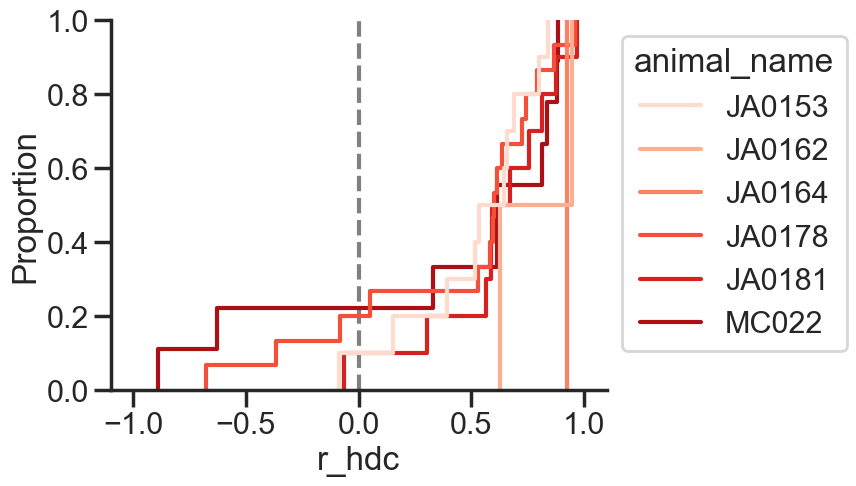

In [35]:
y = 'r_hdc'
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                     'rec_id', 'ep_idx']).max().reset_index()
plt.axvline(x = 0, color = 'gray', ls = '--')

g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Reds')
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# y = 'r_nonhdc'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'GnBu')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# y = 'r_rand'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Greys')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xlim(-1.1, 1.1)
# plt.savefig(f'ecdf_hr_isomap-dyn-by-mouse_{y}.pdf', transparent = True)

(-1.1, 1.1)

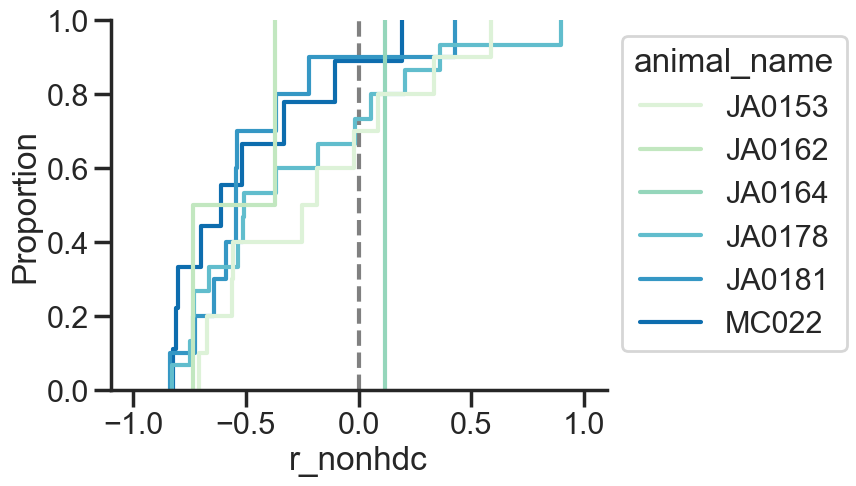

In [36]:
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                     'rec_id', 'ep_idx']).max().reset_index()
plt.axvline(x = 0, color = 'gray', ls = '--')
# y = 'r_hdc'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Reds')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

y = 'r_nonhdc'
g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'GnBu')
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xlim(-1.1, 1.1)
# plt.savefig(f'ecdf_hr_isomap-dyn-by-mouse_{y}.pdf', transparent = True)

(-1.0, 1.0)

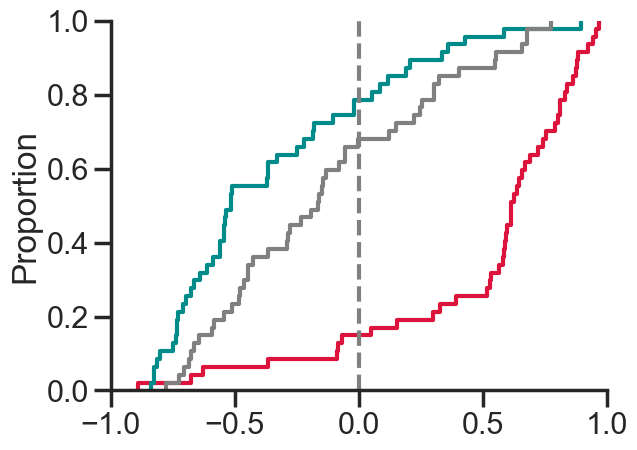

In [37]:
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                                 'rec_id', 'ep_idx']).max().reset_index()

a1 = _inp_plot['r_hdc'].values
b1 = _inp_plot['r_nonhdc'].values
c1 = _inp_plot['r_rand'].values

sns.ecdfplot(a1, color = 'crimson')
sns.ecdfplot(b1, color = 'darkcyan')
sns.ecdfplot(c1, color = 'Gray')
plt.axvline(x = 0, color = 'gray', ls = '--')
plt.xlim(-1, 1)

# filepath = save_dir / f'ecdf_hr_isomap-dyn_all.pdf'
# plt.savefig(filepath, transparent = True)

In [38]:
_inp_plot.describe()

,ep_idx,r_hdc,r_nonhdc,r_rand,min_rad
count,47.000000,47.000000,47.000000,47.000000,47.000000
mean,36.638298,0.504920,-0.347166,-0.131773,0.192081
std,23.571746,0.445301,0.426822,0.440360,0.172417
min,1.000000,-0.888258,-0.837079,-0.774690,0.001462
25%,15.500000,0.454121,-0.685930,-0.480652,0.034048
50%,35.000000,0.615623,-0.515654,-0.165218,0.139133
75%,50.500000,0.807471,-0.061641,0.236428,0.362020
max,87.000000,0.967526,0.897861,0.777050,0.524892


In [39]:
print('r hdc vs nonhdc')
print(stats.ks_2samp(a1, b1))
print('r hdc vs rand')
print(stats.ks_2samp(a1, c1))
print('r rand vs nonhdc')
print(stats.ks_2samp(b1, c1))

r hdc vs nonhdc
KstestResult(statistic=0.7021276595744681, pvalue=2.1440209394916404e-11, statistic_location=0.2060327575551834, statistic_sign=-1)
r hdc vs rand
KstestResult(statistic=0.6382978723404256, pvalue=2.5904817704210756e-09, statistic_location=0.3251196146516922, statistic_sign=-1)
r rand vs nonhdc
KstestResult(statistic=0.3191489361702128, pvalue=0.016154625944318796, statistic_location=-0.5138041242794893, statistic_sign=1)


In [41]:
# _inp_plot.to_excel(filepath, index=True)

## Lin vel vs manifold radius timecourse

In [42]:
from scipy.optimize import curve_fit
def sigmoid(t, t0, k, base, amplitude):
    """
    Logistic sigmoid.
    t0        : midpoint / inflection point (seconds)
    k         : steepness (s^-1)
    base      : value before rise
    amplitude : total rise
    """
    return base + amplitude / (1 + np.exp(-k * (t - t0)))


def fit_sigmoid(t, signal, p0=None):
    """Fit sigmoid and return (params, covariance, fitted_curve)."""
    if p0 is None:
        t0_guess = t[len(t) // 2]
        k_guess = 3.0
        base_guess = signal[:5].mean()
        amp_guess = signal[-5:].mean() - base_guess
        p0 = [t0_guess, k_guess, base_guess, amp_guess]
    try:
        popt, pcov = curve_fit(sigmoid, t, signal, p0=p0,
                               maxfev=10000,
                               bounds=([-np.inf, 0.1, -np.inf, -np.inf],
                                       [np.inf, 50, np.inf, np.inf]))
        fitted = sigmoid(t, *popt)
        return popt, pcov, fitted
    except RuntimeError:
        print("  WARNING: sigmoid fit did not converge.")
        return None, None, np.full_like(signal, np.nan)



In [43]:
def is_good_epoch(t, signal, popt, pcov, fit, label=''):
    perr = np.sqrt(np.diag(pcov))
    
    # 1. Parameter uncertainty on t0 (your proposed criterion)
    t0_err_ok = perr[0] < 0.4          # t0 uncertain by less than 300 ms
    
    # 2. t0 must be within the time window (catch runaway fits)
    t0_in_window = t[0] < popt[0] < t[-1]
    
    # 3. Amplitude must be in the right direction and meaningful
    amp_ok = popt[3] > 0               # signal rises, not falls
    
    # 4. Goodness of fit: R²
    ss_res = np.sum((signal - fit)**2)
    ss_tot = np.sum((signal - signal.mean())**2)
    r2 = 1 - ss_res / ss_tot
    r2_ok = r2 > 0.4
    
    # 5. Steepness sanity (not a cliff, not flat)
    k_ok = 0.5 < popt[1] < 50
    
    passed = t0_err_ok and t0_in_window and amp_ok and r2_ok and k_ok
    return passed, {'perr_t0': perr[0], 'r2': r2, 'k': popt[1], 
                    't0': popt[0], 'amp': popt[3]}

In [44]:
def test_xcorr_significance(speed, radius, n_shuffles=500, fs=10, to_plot = False):
    """
    Test if cross-correlation peak between speed and radius is statistically significant.
    
    Parameters:
    speed, radius - The two time series to correlate
    n_shuffles - Number of shuffles for null distribution
    fs - Sampling frequency in Hz
    
    Returns:
    is_significant - Boolean indicating if peak is significant (p < 0.05)
    p_value - Empirical p-value
    lag_seconds - Lag at peak in seconds
    """
    # Function to compute maximum cross-correlation
    def compute_xcorr_peak(a, b):
        # Mean-center and compute cross-correlation
        a_centered = a - np.mean(a)
        b_centered = b - np.mean(b)
        xcorr = np.correlate(a_centered, b_centered, mode='full')
        return np.max(np.abs(xcorr))
    
    # Compute actual cross-correlation
    xcorr_actual = np.correlate(speed - np.mean(speed), radius - np.mean(radius), mode='full')
    actual_peak = np.max(np.abs(xcorr_actual))
    
    # Find lag at peak
    peak_idx = np.argmax(np.abs(xcorr_actual))
    lag = peak_idx - (len(speed) - 1)
    lag_seconds = lag / fs
    
    # Perform shuffling test
    shuffle_peaks = np.empty(n_shuffles)
    for i in range(n_shuffles):
        # Randomly shuffle the radius signal
        radius_shuffled = np.random.permutation(radius)
        shuffle_peaks[i] = compute_xcorr_peak(speed, radius_shuffled)
    
    # Compute empirical p-value
    p_value = np.mean(shuffle_peaks >= actual_peak)
    is_significant = p_value < 0.05
    
    # Create simple diagnostic plot
    if to_plot == True:
        plt.figure(figsize=(8, 5))
        plt.hist(shuffle_peaks, bins=10, alpha=0.7, color='gray', label='Null distribution')
        plt.axvline(x=actual_peak, color='red', linestyle='--', 
                    label=f'Observed peak (p={p_value:.3f})')
        plt.xlabel('Peak Cross-Correlation')
        plt.ylabel('Frequency')
        plt.title(f'Lag: {lag_seconds:.3f} seconds')
        plt.legend()
    
    return is_significant, p_value, lag_seconds

#### Extract epochs using stat/run

In [45]:
d_run_onset = {}

20220126_JA0153_lightHR1, ep idx: 41, circmean 201.13077356778888, circstd 11.408500343540915 min rad 0.27601542165580784
len 215, std: 1.67, idx: 2069 - 2109
good epoch (True, {'perr_t0': 0.35994810785416526, 'r2': 0.7391490809430349, 'k': 1.3016630233838402, 't0': 0.0072163961691083895, 'amp': 12.314503425675447}) (True, {'perr_t0': 0.13116986905806788, 'r2': 0.9003525097624444, 'k': 2.1790154003093627, 't0': 0.5263094758847832, 'amp': 0.36003418380451124})
Speed  sigmoid midpoint  t0 = +0.007 s  (±0.360)
Radius sigmoid midpoint  t0 = +0.526 s  (±0.131)
Estimated lag (radius - speed): +1398.1 ms


C:\Users\01\anaconda3\envs\py39\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


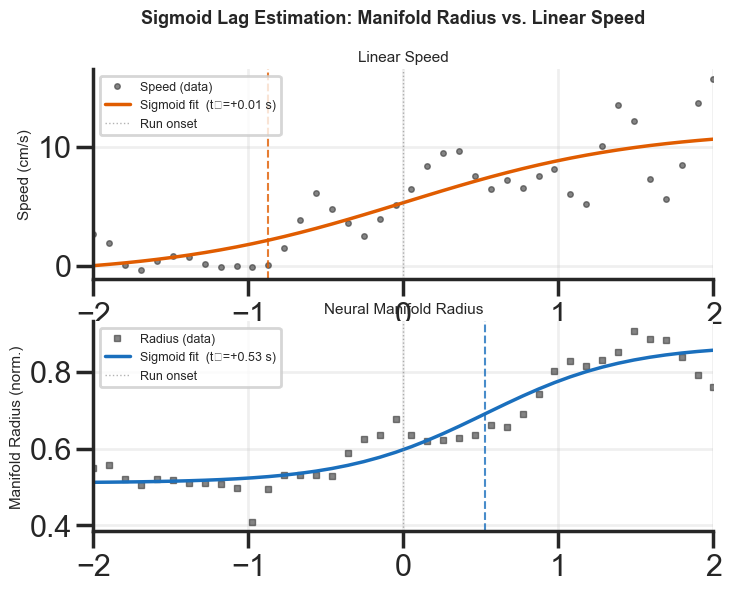

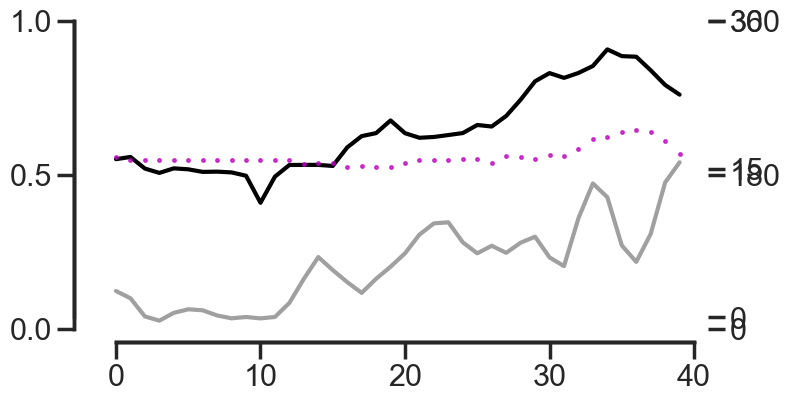

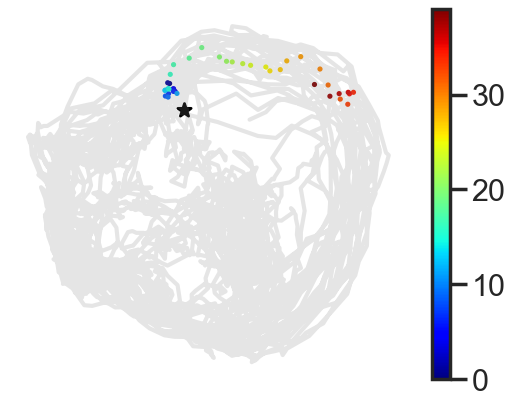


20220302_JA0162_lightHR1, ep idx: 45, circmean 217.15079124941744, circstd 2.505555780445354 min rad 0.39334597101027297
len 430, std: 4.89, idx: 1824 - 1864
good epoch (True, {'perr_t0': 0.05059774258385106, 'r2': 0.7673779945387593, 'k': 20.714401459420714, 't0': 0.1292037004983629, 'amp': 6.5565572527891165}) (True, {'perr_t0': 0.036113422541523, 'r2': 0.9379567285392122, 'k': 9.167536841808545, 't0': 0.16337850719357225, 'amp': 0.1506546197028122})
Speed  sigmoid midpoint  t0 = +0.129 s  (±0.051)
Radius sigmoid midpoint  t0 = +0.163 s  (±0.036)
Estimated lag (radius - speed): +9.5 ms


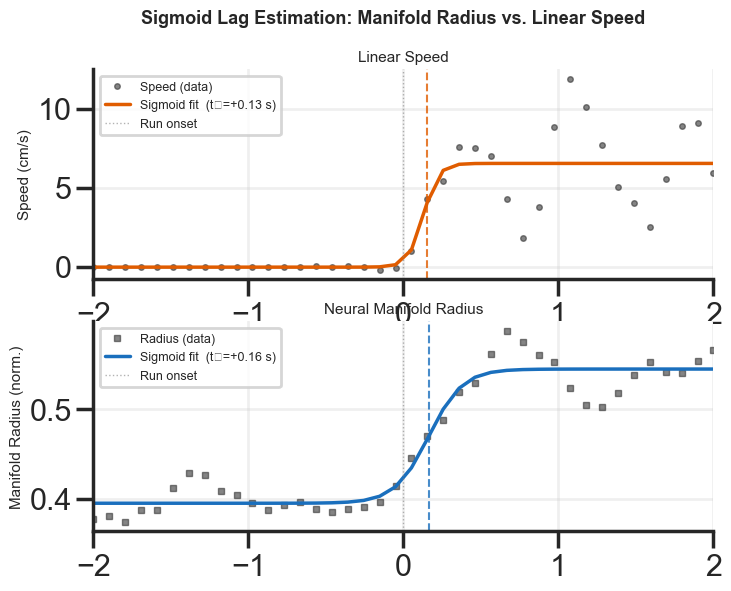

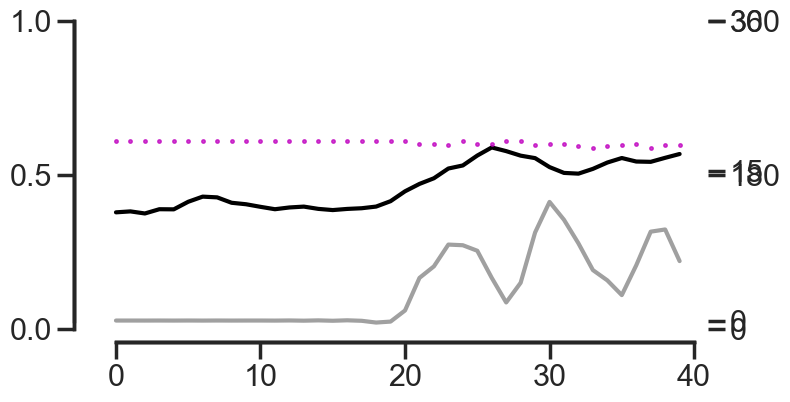

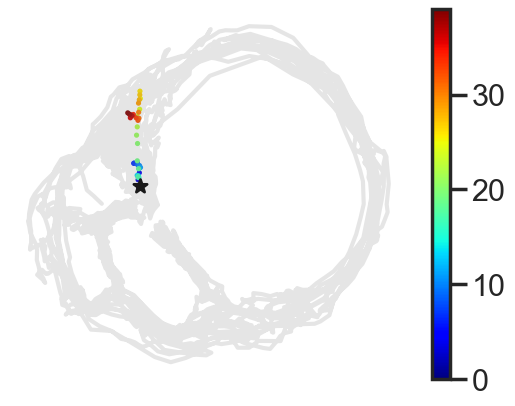


20220302_JA0162_lightHR1, ep idx: 60, circmean 201.5995424827472, circstd 1.881197919492108 min rad 0.32348322699313964
len 70, std: 1.98, idx: 2264 - 2304
good epoch (True, {'perr_t0': 0.0363111005494708, 'r2': 0.8731681116197734, 'k': 19.80671568992728, 't0': 0.10395069633805464, 'amp': 5.837309891994187}) (True, {'perr_t0': 0.048335829021413576, 'r2': 0.9269793419723614, 'k': 5.893759435670169, 't0': -0.7343345515517646, 'amp': 0.18178419515022995})
Speed  sigmoid midpoint  t0 = +0.104 s  (±0.036)
Radius sigmoid midpoint  t0 = -0.734 s  (±0.048)
Estimated lag (radius - speed): -888.2 ms


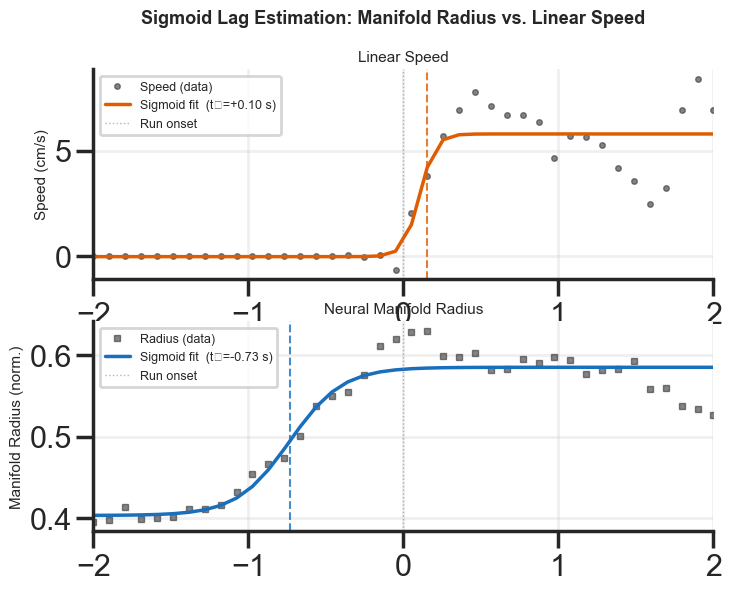

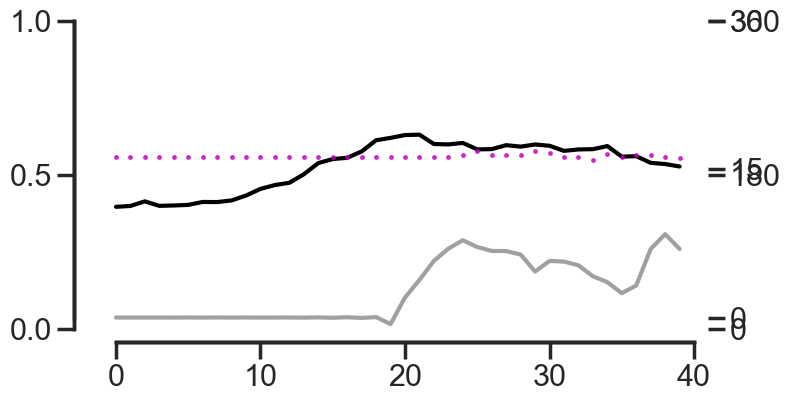

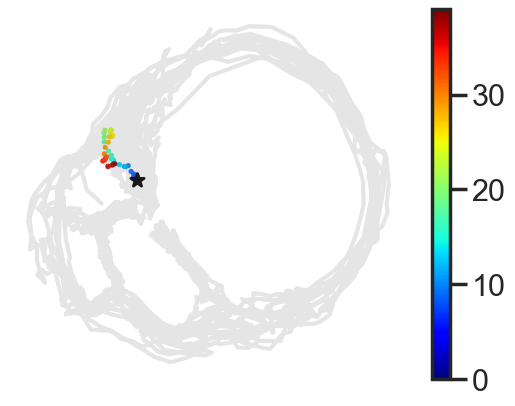


20220302_JA0162_lightHR1, ep idx: 63, circmean 201.37511697052798, circstd 2.352504932042013 min rad 0.3408801619375111
len 50, std: 1.35, idx: 2349 - 2389
good epoch (True, {'perr_t0': 0.07346522072599303, 'r2': 0.7306608516055948, 'k': 12.200951214875433, 't0': 0.03268593182461662, 'amp': 4.319196926083266}) (True, {'perr_t0': 0.06130957969080097, 'r2': 0.9585372704301182, 'k': 2.9406530001340156, 't0': -0.6280697526993114, 'amp': 0.21313702916859828})
Speed  sigmoid midpoint  t0 = +0.033 s  (±0.073)
Radius sigmoid midpoint  t0 = -0.628 s  (±0.061)
Estimated lag (radius - speed): -679.4 ms


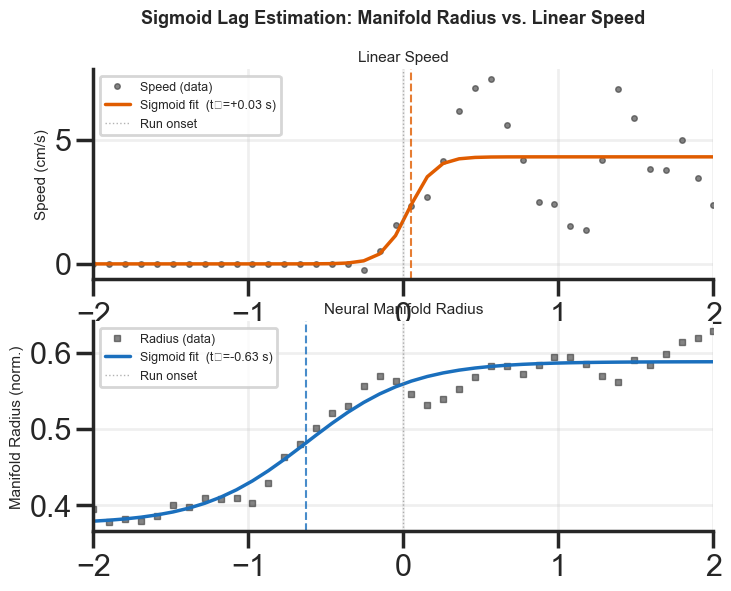

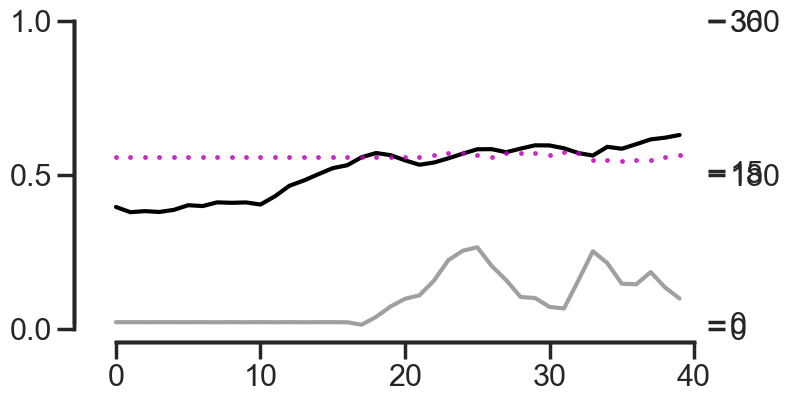

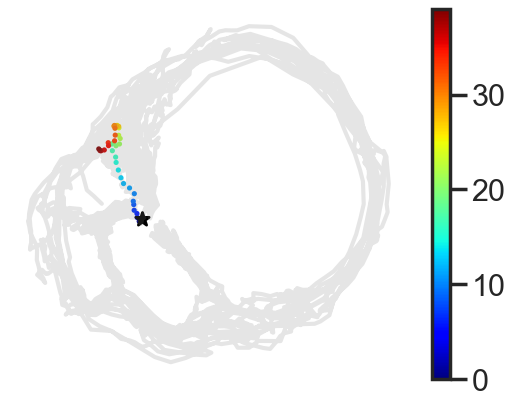


20220302_JA0162_lightHR1, ep idx: 64, circmean 205.99020128474913, circstd 7.228808967321798 min rad 0.5155643675875472
len 160, std: 4.03, idx: 2514 - 2554
good epoch (True, {'perr_t0': 0.03399199422043299, 'r2': 0.8148567600563349, 'k': 29.08696929803094, 't0': 0.056100471850581146, 'amp': 4.565827526681736}) (True, {'perr_t0': 0.031660586686588235, 'r2': 0.969412789583359, 'k': 5.871667896270467, 't0': -0.33029703415878486, 'amp': 0.21221921750053988})
Speed  sigmoid midpoint  t0 = +0.056 s  (±0.034)
Radius sigmoid midpoint  t0 = -0.330 s  (±0.032)
Estimated lag (radius - speed): -381.6 ms


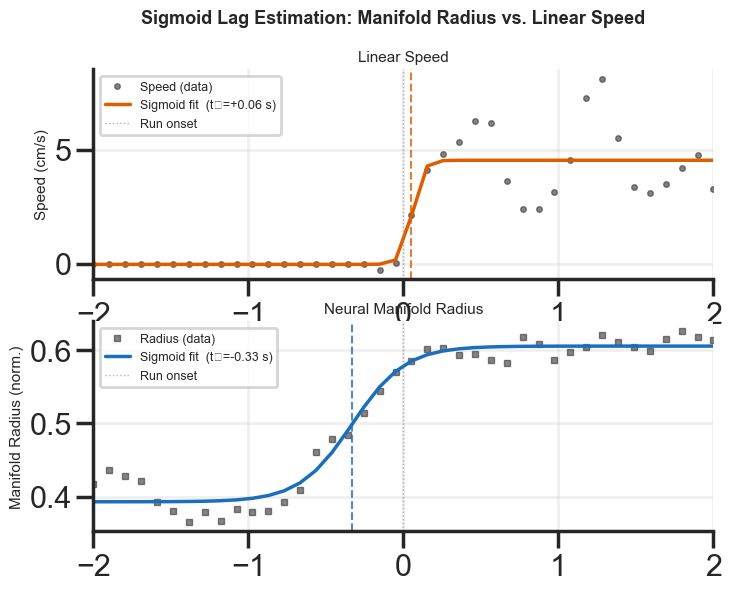

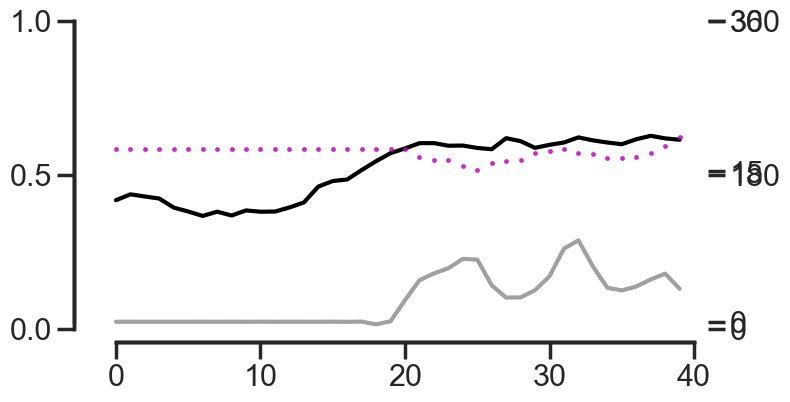

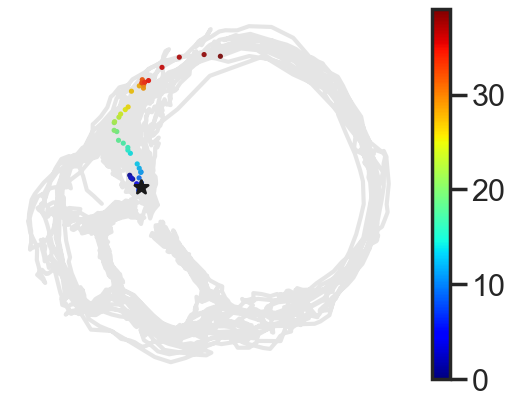


20220302_JA0162_lightHR1, ep idx: 88, circmean 38.75589993370238, circstd 13.73476440194642 min rad 0.5426789697586162
len 155, std: 5.58, idx: 3959 - 3999
good epoch (True, {'perr_t0': 0.11562047486152463, 'r2': 0.5326096352281091, 'k': 49.99999999999932, 't0': -0.03868302751294965, 'amp': 3.84563053544914}) (True, {'perr_t0': 0.36726295943287757, 'r2': 0.8704867811137769, 'k': 1.467652900111318, 't0': -0.8932018261232644, 'amp': 0.40044508529175965})
Speed  sigmoid midpoint  t0 = -0.039 s  (±0.116)
Radius sigmoid midpoint  t0 = -0.893 s  (±0.367)
Estimated lag (radius - speed): -944.5 ms


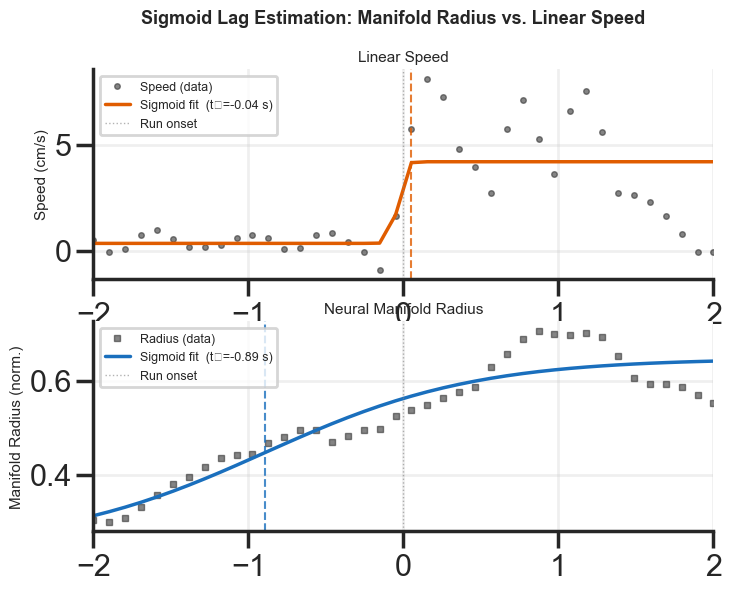

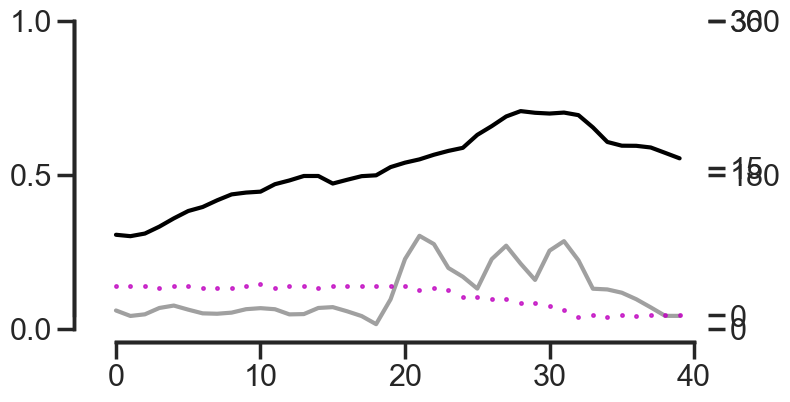

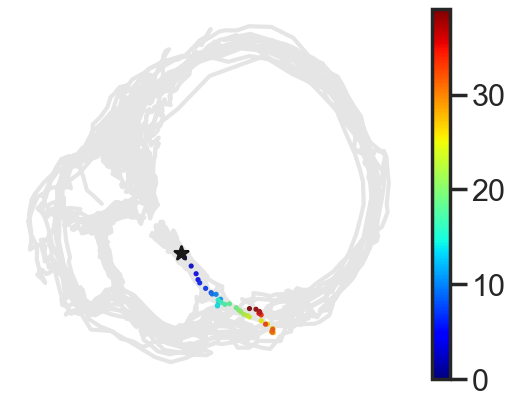


20220815_JA0181_lightHR1, ep idx: 4, circmean 191.10900259507028, circstd 13.509430226581388 min rad 0.4274888199178195
len 60, std: 2.33, idx: 1054 - 1094
good epoch (True, {'perr_t0': 0.11979024821910599, 'r2': 0.542271572509345, 'k': 49.99999999979585, 't0': 0.03675670567311878, 'amp': 5.488851221881643}) (True, {'perr_t0': 0.08912447480563339, 'r2': 0.708270282992491, 'k': 8.035464173541795, 't0': -0.9109114471466797, 'amp': 0.2059480107034378})
Speed  sigmoid midpoint  t0 = +0.037 s  (±0.120)
Radius sigmoid midpoint  t0 = -0.911 s  (±0.089)
Estimated lag (radius - speed): -962.2 ms


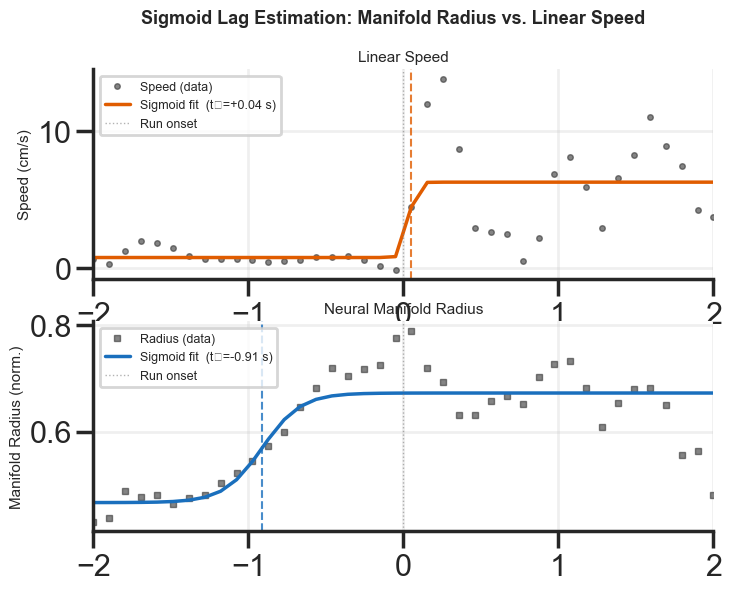

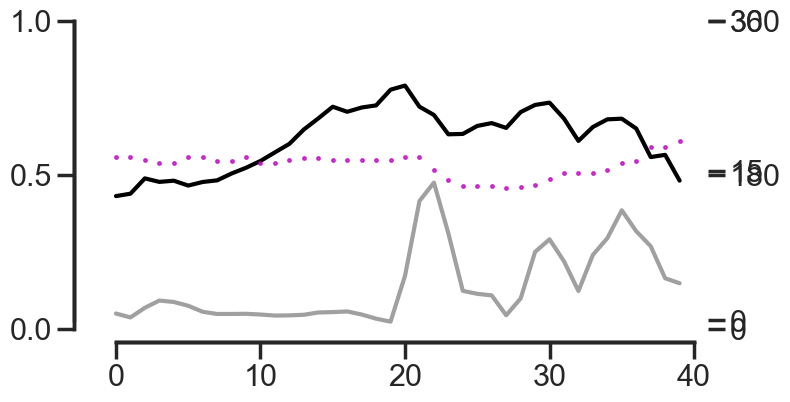

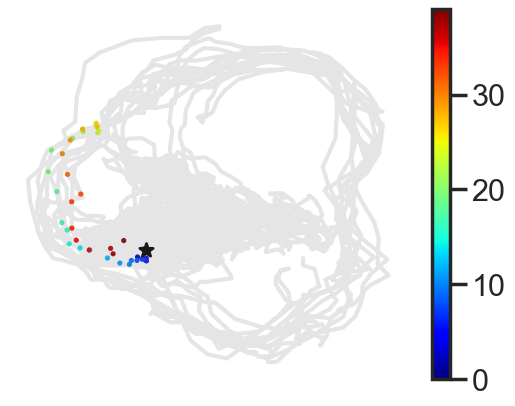


20220712_MC022_lightHR1, ep idx: 12, circmean 129.77505593177804, circstd 11.169741848559768 min rad 0.4619271799096692
len 115, std: 0.99, idx: 609 - 649
good epoch (True, {'perr_t0': 0.12575837379440022, 'r2': 0.45947878094815164, 'k': 49.999999949617155, 't0': -0.4729959613973064, 'amp': 5.494182229082591}) (True, {'perr_t0': 0.21972665451519094, 'r2': 0.5041723979053931, 'k': 4.33130974174245, 't0': -1.05954609939131, 'amp': 0.17522117956034755})
Speed  sigmoid midpoint  t0 = -0.473 s  (±0.126)
Radius sigmoid midpoint  t0 = -1.060 s  (±0.220)
Estimated lag (radius - speed): -598.0 ms


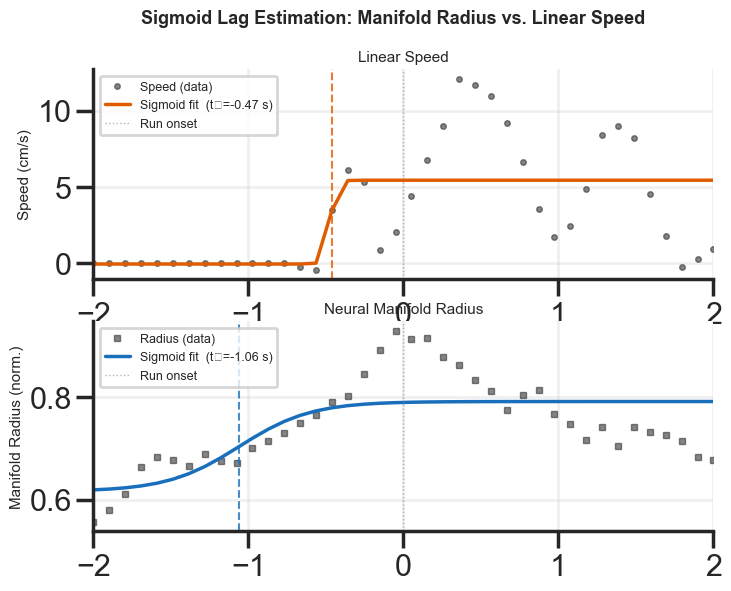

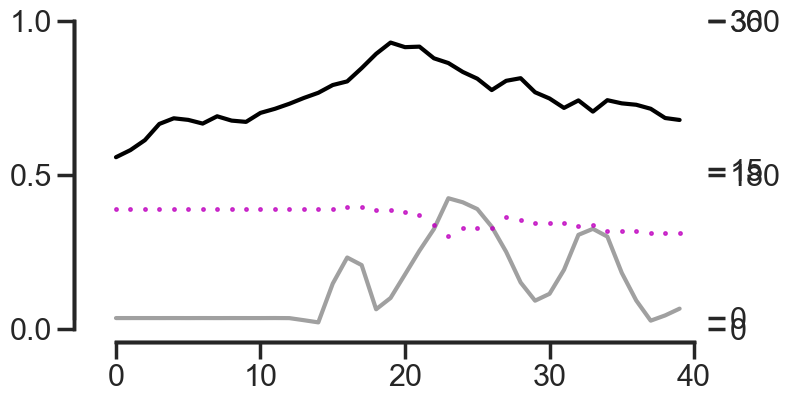

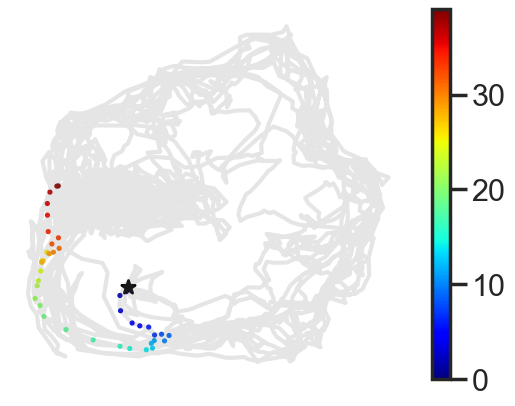


20220126_JA0153_darkHR1, ep idx: 16, circmean 188.54556858518447, circstd 14.279717780647054 min rad 0.16175338188391425
len 130, std: 1.13, idx: 1409 - 1449
good epoch (True, {'perr_t0': 0.36922115310388404, 'r2': 0.8700634673259424, 'k': 1.7875723111307924, 't0': 1.2324607700514985, 'amp': 32.1150828168346}) (True, {'perr_t0': 0.05547199788207786, 'r2': 0.8907606175663217, 'k': 7.046596334187838, 't0': -0.5158743600850197, 'amp': 0.46725223383136555})
Speed  sigmoid midpoint  t0 = +1.232 s  (±0.369)
Radius sigmoid midpoint  t0 = -0.516 s  (±0.055)
Estimated lag (radius - speed): -464.6 ms


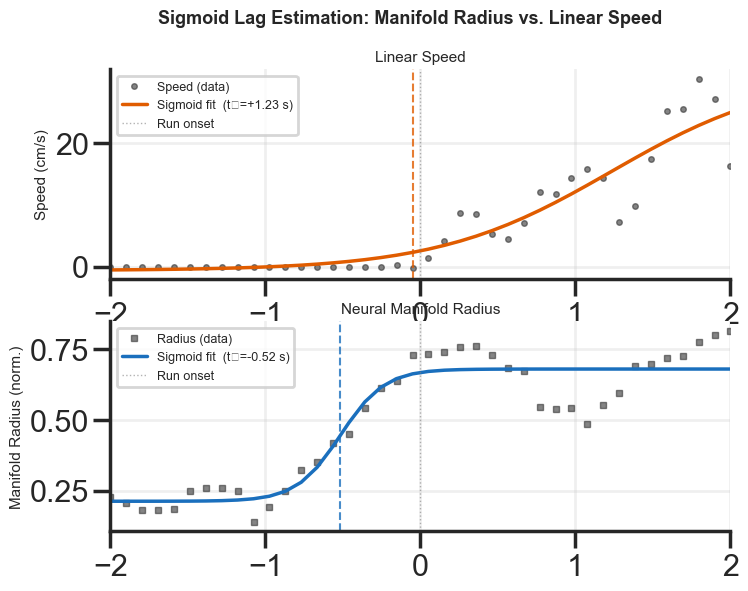

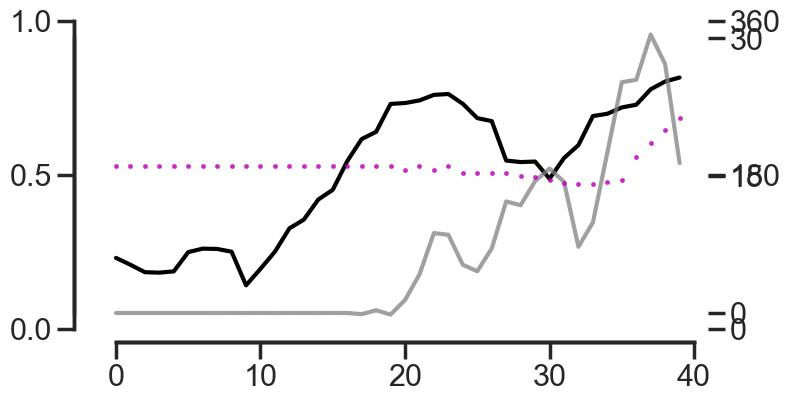

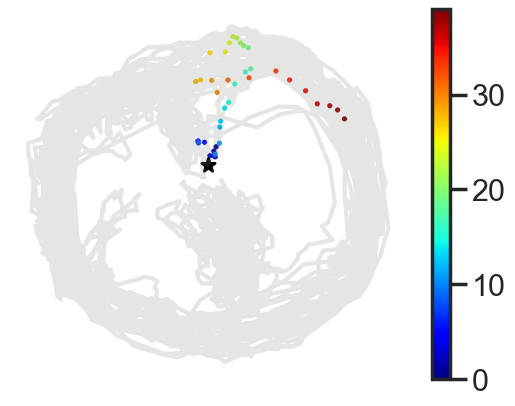


20220126_JA0153_darkHR1, ep idx: 22, circmean 126.98351901438846, circstd 6.620247778847675 min rad 0.28948935050341645
len 175, std: 9.1, idx: 1799 - 1839
good epoch (True, {'perr_t0': 0.10265077360463686, 'r2': 0.41865845331398743, 'k': 43.65878931342027, 't0': 0.16588863152400884, 'amp': 15.992605069507555}) (True, {'perr_t0': 0.252811033611428, 'r2': 0.936703019470521, 'k': 1.9639362037837362, 't0': -1.3897784750941384, 'amp': 0.43341822772559363})
Speed  sigmoid midpoint  t0 = +0.166 s  (±0.103)
Radius sigmoid midpoint  t0 = -1.390 s  (±0.253)
Estimated lag (radius - speed): -1543.6 ms


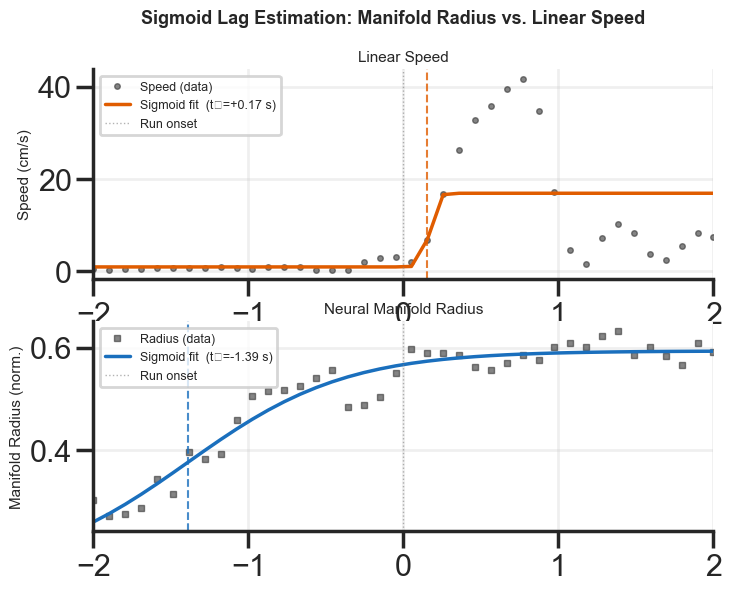

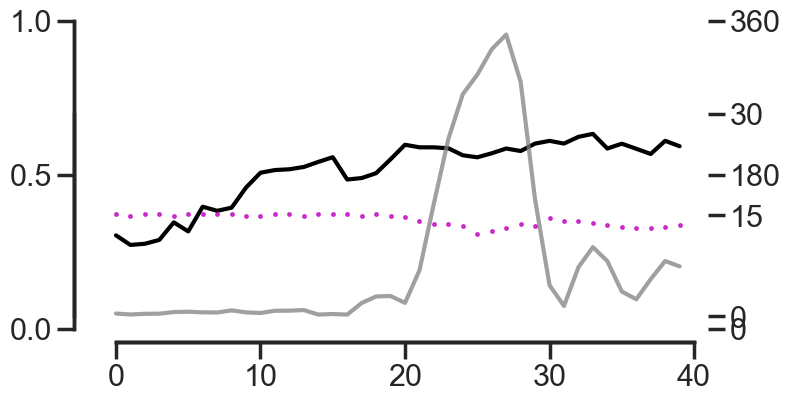

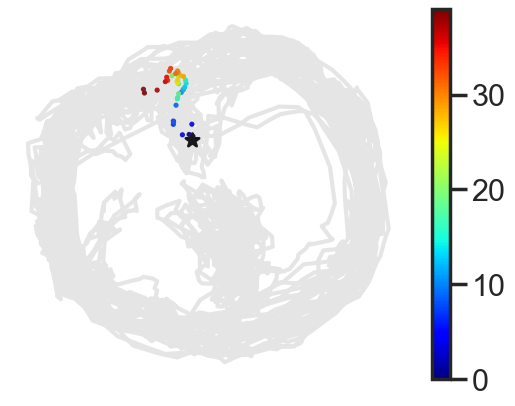


20220302_JA0162_darkHR1, ep idx: 23, circmean 206.54947931077464, circstd 4.455832949717459 min rad 0.14577741475206318
len 85, std: 2.68, idx: 1524 - 1564
bad epoch (False, {'perr_t0': 0.6589301518424392, 'r2': 0.2062038586855428, 'k': 3.61893997961262, 't0': -1.333031582903622, 'amp': 3.3265072169689307}) (True, {'perr_t0': 0.1303031160342229, 'r2': 0.7472704028283678, 'k': 4.1184662558870935, 't0': 0.8587401634732008, 'amp': 0.12733645368995422})
20220302_JA0162_darkHR1, ep idx: 36, circmean 146.55975522006992, circstd 6.88320085801345 min rad 0.23433412866578215
len 240, std: 12.8, idx: 2099 - 2139
good epoch (True, {'perr_t0': 0.07470809724327646, 'r2': 0.6950072532313278, 'k': 13.935379149680925, 't0': 0.11598053364727512, 'amp': 4.115273728906722}) (True, {'perr_t0': 0.1542945525688681, 'r2': 0.5061653187456743, 'k': 6.861445913740249, 't0': -0.7668921786485319, 'amp': 0.19706629566036232})
Speed  sigmoid midpoint  t0 = +0.116 s  (±0.075)
Radius sigmoid midpoint  t0 = -0.767 s 

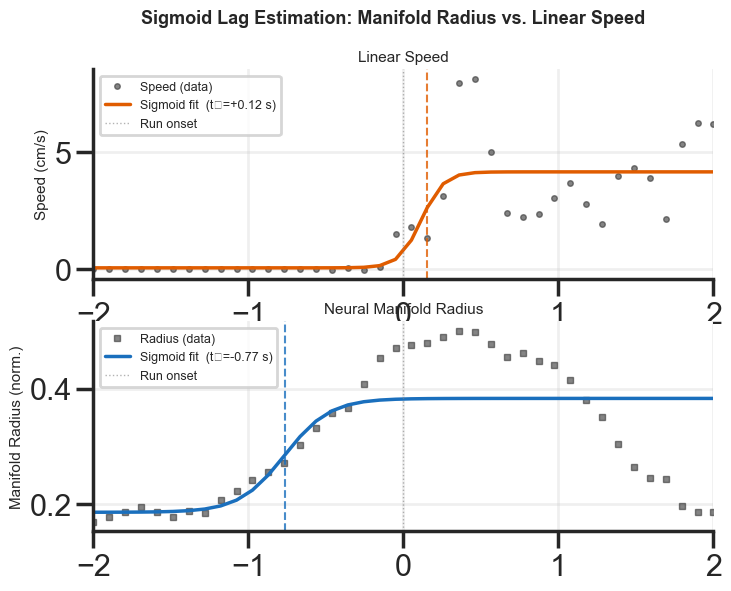

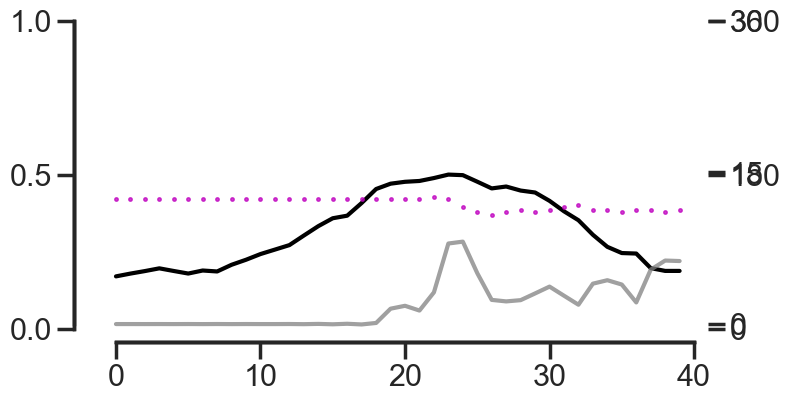

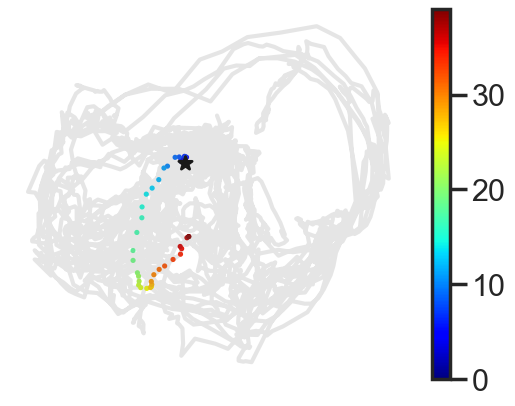


20220302_JA0162_darkHR1, ep idx: 41, circmean 131.3801458175364, circstd 9.510799700719895 min rad 0.335924912135506
len 500, std: 3.97, idx: 2924 - 2964
good epoch (True, {'perr_t0': 0.03645933256587686, 'r2': 0.8472593692447932, 'k': 22.386244390974372, 't0': -0.2660512877026263, 'amp': 5.796888385315755}) (True, {'perr_t0': 0.024696513983747358, 'r2': 0.979635472436959, 'k': 6.309571096206461, 't0': -0.30528931172114304, 'amp': 0.40196286045074353})
Speed  sigmoid midpoint  t0 = -0.266 s  (±0.036)
Radius sigmoid midpoint  t0 = -0.305 s  (±0.025)
Estimated lag (radius - speed): -48.9 ms


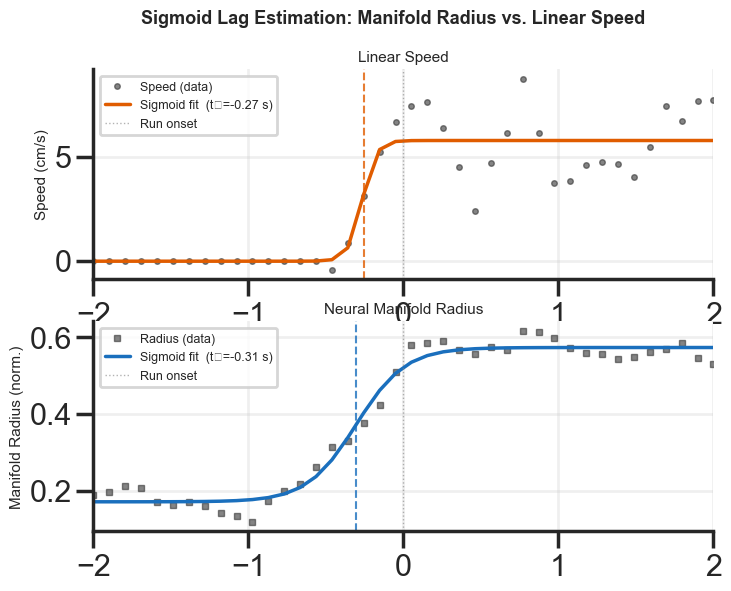

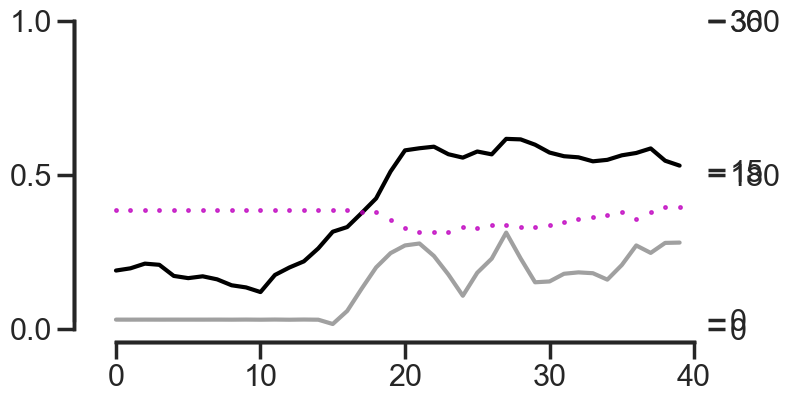

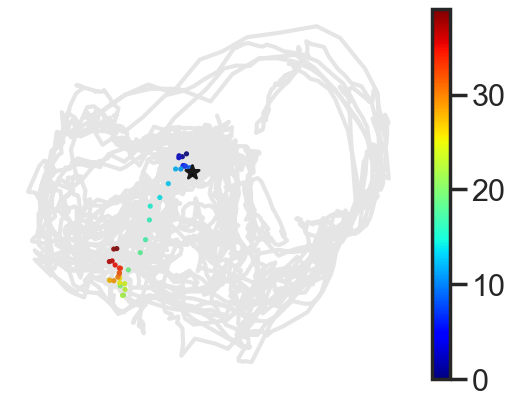


20220302_JA0162_darkHR1, ep idx: 65, circmean 302.1609248149504, circstd 7.419932767732687 min rad 0.08737849735235455
len 50, std: 2.75, idx: 4234 - 4274
bad epoch (True, {'perr_t0': 0.1475464039227331, 'r2': 0.6761268072181805, 'k': 4.333566790358574, 't0': -0.5108591644664914, 'amp': 4.528513891723673}) (False, {'perr_t0': 5.254563507946076, 'r2': 0.8509635256371412, 'k': 0.973229336984273, 't0': -3.1752361649931498, 'amp': 0.8841201128905378})
20220822_JA0178_darkHR1, ep idx: 42, circmean 343.79301276134754, circstd 9.475602229325109 min rad 0.46805810095118644
len 115, std: 68.8, idx: 1944 - 1984
bad epoch (True, {'perr_t0': 0.12199451811149063, 'r2': 0.5405673103230035, 'k': 49.9999999999999, 't0': -0.08294101570400567, 'amp': 5.860613065002755}) (False, {'perr_t0': 1.3536575227405474, 'r2': 0.9096251027299391, 'k': 0.9648836584262126, 't0': -1.7483268753367098, 'amp': 0.5663807899758321})
20220815_JA0181_darkHR1, ep idx: 9, circmean 220.86306417857884, circstd 6.71102746608554 

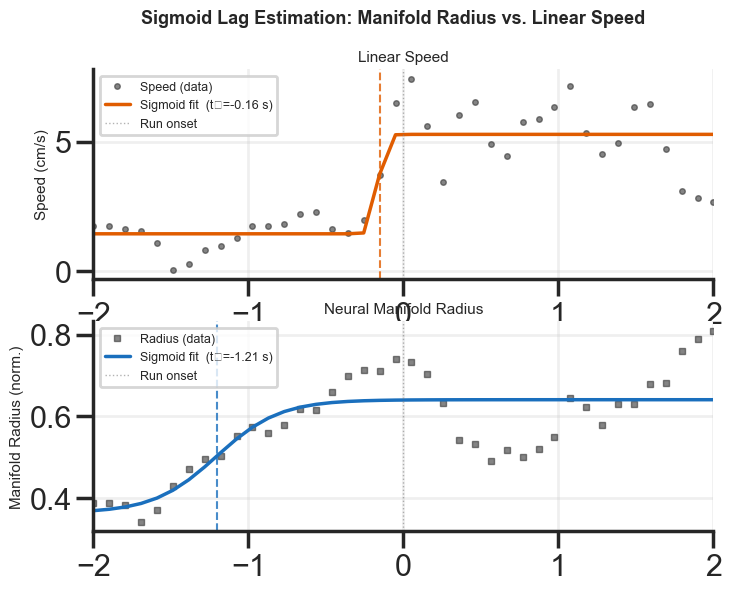

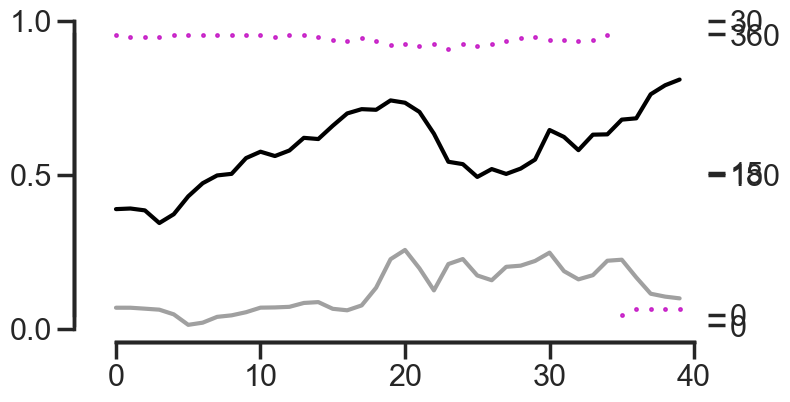

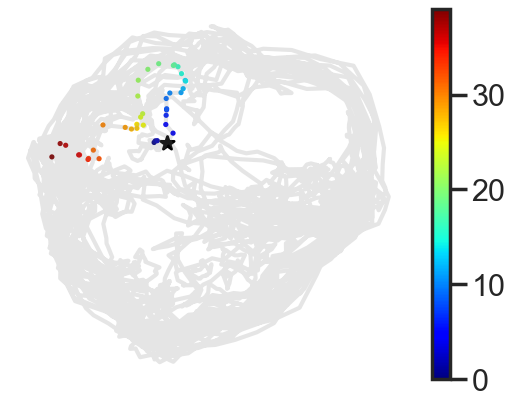


20220818_JA0181_darkHR1, ep idx: 112, circmean 248.74937262955757, circstd 11.26544882937501 min rad 0.2831988047437175
len 90, std: 1.76, idx: 3979 - 4019
good epoch (True, {'perr_t0': 0.07099863280392248, 'r2': 0.6123053735555952, 'k': 49.9999999999956, 't0': 0.05825882556179573, 'amp': 4.537445712295941}) (True, {'perr_t0': 0.042819616455185394, 'r2': 0.9283222025386888, 'k': 7.744886907579844, 't0': -0.08979736808584227, 'amp': 0.4239417043405121})
Speed  sigmoid midpoint  t0 = +0.058 s  (±0.071)
Radius sigmoid midpoint  t0 = -0.090 s  (±0.043)
Estimated lag (radius - speed): -243.6 ms


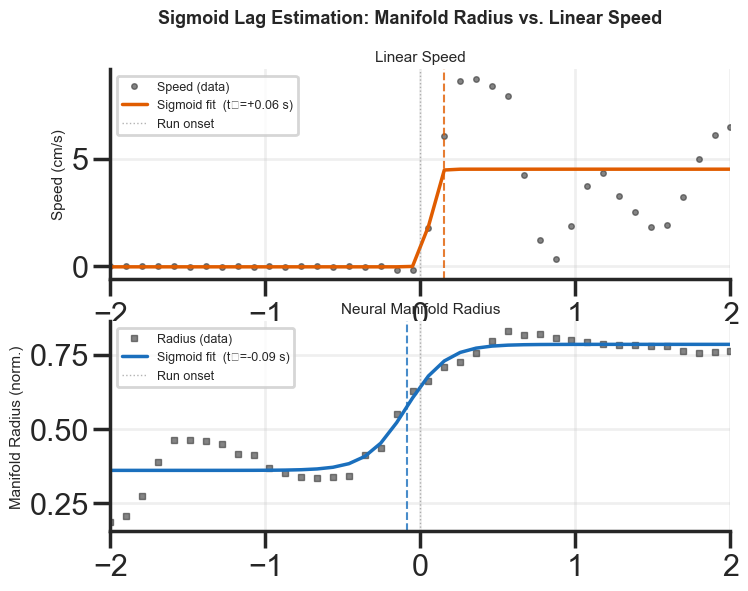

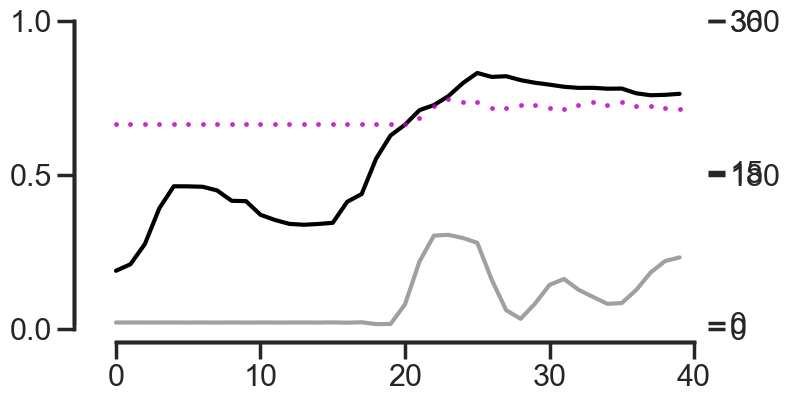

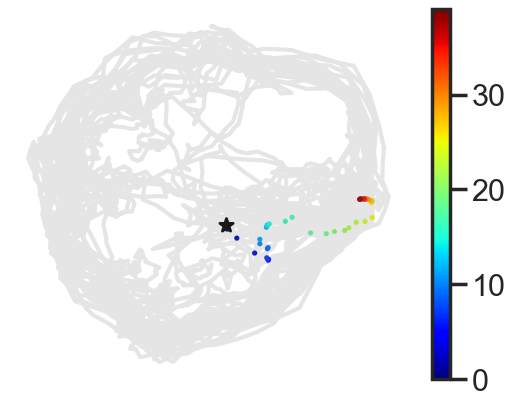


20220818_JA0181_darkHR1, ep idx: 119, circmean 36.594445969609616, circstd 10.45759300864278 min rad 0.39240255262229545
len 130, std: 1.34, idx: 4229 - 4269
good epoch (True, {'perr_t0': 0.12038366717710595, 'r2': 0.49585194408011013, 'k': 12.51547916001137, 't0': -0.03561094450362974, 'amp': 4.3429250289025285}) (True, {'perr_t0': 0.07982002774500796, 'r2': 0.9007071947098363, 'k': 3.624963755654106, 't0': -0.21047886552836018, 'amp': 0.3258596716198323})
Speed  sigmoid midpoint  t0 = -0.036 s  (±0.120)
Radius sigmoid midpoint  t0 = -0.210 s  (±0.080)
Estimated lag (radius - speed): -159.2 ms


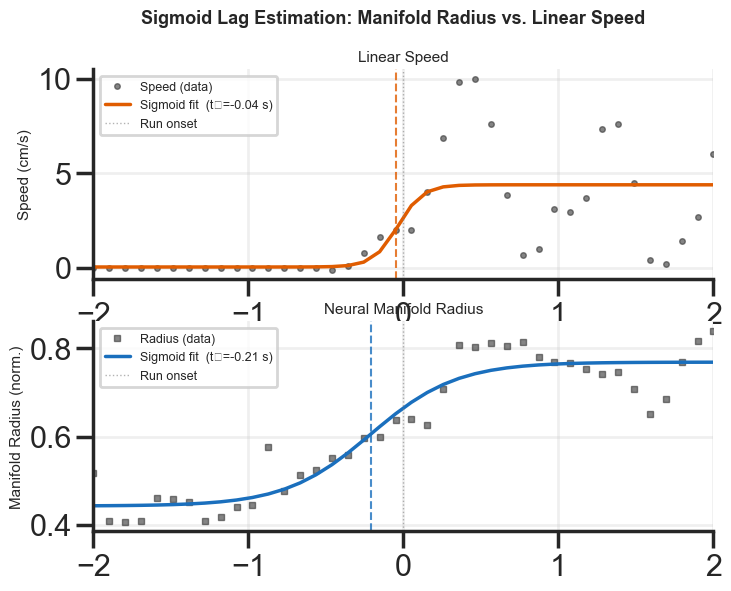

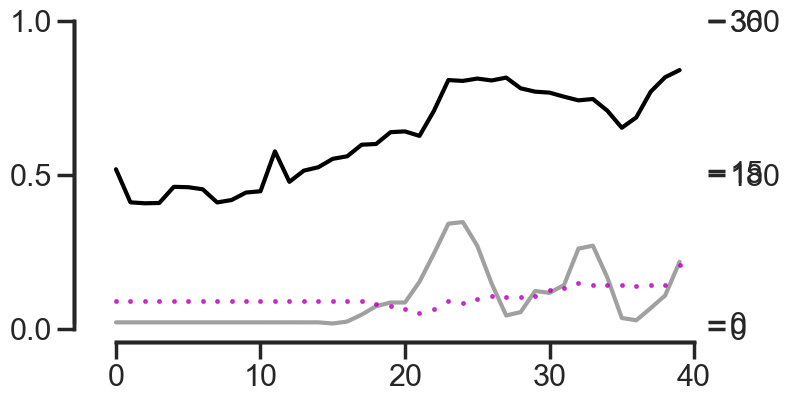

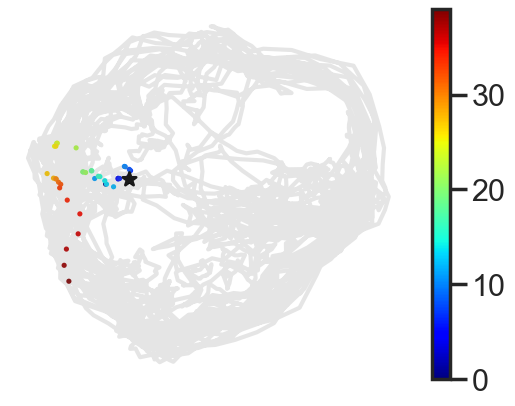

,rec_id,epoch,aligned_speed,speed_onset_t,fit_s,lag,aligned_yaw,aligned_radius,fit_r,t0_radius,time
0,20220126_JA0153_lightHR1,41,2.643606,-0.871795,0.001199,1.398104,200.426034,0.550029,0.511854,0.526309,-2.000000
1,20220126_JA0153_lightHR1,41,1.909537,-0.871795,0.112077,1.398104,196.887348,0.557211,0.512217,0.526309,-1.897436
2,20220126_JA0153_lightHR1,41,0.072097,-0.871795,0.236196,1.398104,196.887348,0.519601,0.512671,0.526309,-1.794872
3,20220126_JA0153_lightHR1,41,-0.358566,-0.871795,0.374763,1.398104,196.887348,0.505424,0.513236,0.526309,-1.692308
4,20220126_JA0153_lightHR1,41,0.430711,-0.871795,0.528995,1.398104,196.887348,0.520216,0.513940,0.526309,-1.589744


In [47]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
pref_dir_thr = 45 
speed_thr = 5
ep_offset = 30
to_plot = True
# 25s
ep_end = 40
n_samples = 40   # samples per epoch
t = np.linspace(-2, 2, n_samples)   # 4 s window centred on run onset
ls_lag, ls_df = [], []

for k in d_hr_emb.keys():

    if 'HR1' not in k:
        continue
    d_run_onset[k] = {}
    aligned_speed, aligned_yaw, aligned_radius = [], [], []

    
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw'] + 180
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
    dyaw = compute_dYaw(measured_yaw)
    # sampling 10 Hz, 100ms
    ang_vel = dyaw*100
    lin_speed = tmp['lin_vel']
    _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    # find stat, run, rot epochs
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
    # get stat epochs
    stat_epoch = consecutive(stat_idx)
    run_epoch = consecutive(run_idx)
    
    for ep_idx, ep in enumerate(stat_epoch):
        # at least 3s and no change in az
        if (len(ep) > 40):
            # if ep_idx != 114:
            #     continue
            start, end = ep[-1]-20, ep[-1] + 20
            if ep.size > 250:
                end = start + ep_end
            if rad_manifold_norm[start:end].max() - rad_manifold_norm[start:end].min() > 0.2:
                offman_ep_flag = True
            else:
                continue
            if ep[0] - ep_offset < 1:
                continue
                
            angles = np.deg2rad(measured_yaw[start:end])
            circstd = stats.circstd(angles)
            circmean = stats.circmean(angles)
            circstd = np.rad2deg(circstd)
            this_yaw = np.rad2deg(circmean)
           
            if circstd > 15:
                # print(f'High circ std {circstd}')
                continue
            baseline_speed = lin_speed[start:ep[-1]].mean()
            onset_speed = lin_speed[ep[-1]: ep[-1] + 5].mean()
            if  baseline_speed > 2 or onset_speed < 4:
                # print(f'Base lin speed {baseline_speed}, onset {onset_speed}')
                continue
            if angles.size != 40:
                continue
            print(f'{k}, ep idx: {ep_idx}, circmean {this_yaw}, circstd {circstd} min rad {rad_manifold_norm[ep[:ep_end]].min()}')
            print(f'len {len(ep)}, std: {round(np.std(measured_yaw[ep]), 2)}, idx: {start} - {end}')
            offset = rad_manifold_norm[start:end].argmin()

            # Convert to arrays
            # aligned_speed.append(lin_speed[start:end])
            # aligned_radius.append(rad_manifold_norm[start:end])
            # aligned_yaw.append(measured_yaw[start:end])

            speed = lin_speed[start:end]
            radius = rad_manifold_norm[start:end]
            epoch_yaw =  measured_yaw[start:end]

            p0_speed  = [0.0,  4.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
            p0_radius = [-0.5, 3.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
            
            popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
            popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
            
            t0_speed  = popt_s[0] if popt_s is not None else np.nan
            t0_radius = popt_r[0] if popt_r is not None else np.nan
            # define spped onset as fit speed crossing 2cm/s
            speed_onset_t = t[np.where(fit_s > 2)[0][0]]
            lag = t0_radius - speed_onset_t   # negative → radius leads speed
            perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
            perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4

            is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
            is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

            if is_good_speed[0] & is_good_rad[0]:
                print(f'good epoch {is_good_speed} {is_good_rad}')
            else:
                print(f'bad epoch {is_good_speed} {is_good_rad}')
                continue
            
            print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
            print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
            print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
            
            ls_lag.append(lag)
            tmp_df = pd.DataFrame({'rec_id': k, 'epoch': ep_idx, 'aligned_speed': speed, 'speed_onset_t': speed_onset_t, 'fit_s':fit_s, 'lag': lag,
                          'aligned_yaw':epoch_yaw, 'aligned_radius': radius, 'fit_r':fit_r, 't0_radius':t0_radius, 'time':t,
                          })
            ls_df.append(tmp_df)
    

            if to_plot == True:

                fig, axes = plt.subplots(2, 1, figsize=(8, 6))
                fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                             fontsize=13, fontweight='bold', y=0.98)
                
                # --- Panel 1: Speed ---
                ax = axes[0]
                ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
                ax.plot(t, fit_s, '-', color='#e05c00', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
                ax.axvline(speed_onset_t, color='#e05c00', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Speed (cm/s)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Linear Speed', fontsize=11)
                ax.grid(True, alpha=0.3)
                
                # --- Panel 2: Radius ---
                ax = axes[1]
                ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
                ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
                ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Neural Manifold Radius', fontsize=11)
                ax.grid(True, alpha=0.3)


                f, ax = plt.subplots(1, figsize = (8, 4))
                ax.plot(rad_manifold_norm[start:end], color = 'k',)
                ax.set_yticks([0, 0.5, 1])
                ax_1 = ax.twinx()
                ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 0.75)
                ax_1.set_yticks([0, 15, 30])
                ax_2 = ax.twinx()
                ax_2.plot( measured_yaw[start:end], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
                ax_2.set_yticks([0, 180, 360])
                sns.despine(offset = 10, trim = True)
                # plt.savefig(f'line_vel_{k}_{ep_idx}.pdf', transparent = True)
                time.sleep(0.2)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = isomap[start:end, 0], isomap[start:end, 1]
                u = np.diff(x_tmp)
                v = np.diff(y_tmp)
                pos_x = x_tmp[:-1] + u/2
                pos_y = y_tmp[:-1] + v/2
                norm = np.sqrt(u**2+v**2) 
                plt.plot(isomap[:, 0], isomap[:, 1], c = 'gray', alpha = 0.2)
                
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:x_tmp.size], 
                            cmap = 'jet')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(isomap[start + offset, 0], isomap[start + offset, 1], c = 'k', s = 100, marker = "*")
                plt.axis('off')
                # plt.savefig(f'scatter_isomap-traj_{k}_{ep_idx}.pdf', transparent = True)

    #             f.legend(loc='outside upper right')
                # f.tight_layout()

                plt.show()
                print('')
            # break
        # d_run_onset[k]['aligned_speed'] = aligned_speed
        # d_run_onset[k]['aligned_radius'] = aligned_radius
        # d_run_onset[k]['aligned_yaw'] = aligned_yaw


        
        # break
    # break
df_run_onset = pd.concat(ls_df)
df_run_onset.head()

In [48]:
df_run_onset.epoch.unique().size

14

In [52]:
spped_onset_t

0.0512820512820511

In [54]:
spped_onset_t

-0.05128205128205132

#### Extract epochs using rolling window

In [528]:
# Skip the epoch-based approach and work directly with continuous data
fs = 10  # Assuming 30 frames per second
speed_threshold = 5  # cm/s
radius_threshold = 0.1  # Relative change threshold
min_separation = fs
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1) 
ls_df = []
for k in d_hr_emb.keys():

    if 'HR' not in k:
        continue
    print(k)
    d_run_onset[k] = {}
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    emb_x, emb_y = isomap[:, 0], isomap[:, 1]
    measured_yaw = tmp['measured_yaw'] + 180
    measured_yaw_rad = np.deg2rad(measured_yaw)
    dyaw = compute_dYaw(measured_yaw)
    # sampling 10 Hz, 100ms
    ang_vel = dyaw*100
    lin_speed = tmp['lin_vel']
     # find stat, run, rot epochs
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius_runmask(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    # Find movement onset events with clean preceding stationary periods
    onset_events = []
    i = fs*3  # Start after first 3 seconds
    
    while i < len(lin_speed) - fs*3:  # Skip last 3 seconds
        # Check if this is a transition from stationary to moving
        if (np.mean(lin_speed[i-10:i]) < 1 and 
            np.mean(lin_speed[i:i+5]) > 4):
        
            # Stable heading
            # circmean = stats.circmean(measured_yaw_rad[i-5:i+10])
            circstd = stats.circstd(measured_yaw_rad[i-10:i+10])
            circstd = np.rad2deg(circstd)
            if circstd > 10:
                i += 1 
                continue
            
            # Find the precise frame where speed crosses threshold
            onset_frame = None
            for j in range(i-5, i+5):
                if lin_speed[j] > speed_threshold:
                    onset_frame = j
                    break
            
            if onset_frame is not None:
                onset_events.append(onset_frame)
                # Skip ahead to avoid double counting nearby transitions
                i = onset_frame + min_separation
                
            else:
                i += 1
        else:
            i += 1
    
    # For each onset event, extract a window of data
    pre_frames = 15  # 1.5 seconds before
    post_frames = 20  # 2 seconds after

    for onset in onset_events:
        if onset > pre_frames and onset + post_frames < len(lin_speed):
            window = np.arange(onset - pre_frames, onset + post_frames)
            # choose epochs with off ring dynamics
            if rad_manifold_norm[window].min() > 0.4:
                continue
            epoch_id = k + '_' + str(onset)
            tmp_df = pd.DataFrame({'epoch_id':epoch_id, 'epoch_speed': lin_speed[window], 'epoch_ring_rad': rad_manifold_norm[window], 'epoch_yaw': measured_yaw[window],
                                  'epoch_emb_x': emb_x[window], 'epoch_emb_y': emb_y[window], 'time':t, 'rec_id':k    })
            ls_df.append(tmp_df)

df_stat2run = pd.concat(ls_df)
df_stat2run.head()

20220126_JA0153_lightHR1
20220302_JA0162_lightHR1
20220419_JA0164_lightHR1
20220819_JA0178_lightHR1
20220822_JA0178_lightHR1
20220812_JA0181_lightHR1
20220815_JA0181_lightHR1
20220818_JA0181_lightHR1
20220712_MC022_lightHR1
20220126_JA0153_darkHR1
20220302_JA0162_darkHR1
20220419_JA0164_darkHR1
20220819_JA0178_darkHR1
20220822_JA0178_darkHR1
20220906_JA0178_darkHR1
20220812_JA0181_darkHR1
20220815_JA0181_darkHR1
20220818_JA0181_darkHR1
20220712_MC022_darkHR1


,epoch_id,epoch_speed,epoch_ring_rad,epoch_yaw,epoch_emb_x,epoch_emb_y,time,rec_id
0,20220302_JA0162_lightHR1_1846,0.003150,0.420467,219.0,-3.408711,4.327514,-1.5,20220302_JA0162_lightHR1
1,20220302_JA0162_lightHR1_1846,-0.002320,0.403037,219.0,-3.075265,4.221943,-1.4,20220302_JA0162_lightHR1
2,20220302_JA0162_lightHR1_1846,0.000750,0.398353,219.0,-2.996255,4.157624,-1.3,20220302_JA0162_lightHR1
3,20220302_JA0162_lightHR1_1846,0.001622,0.390018,219.0,-2.837636,4.104202,-1.2,20220302_JA0162_lightHR1
4,20220302_JA0162_lightHR1_1846,-0.004770,0.382580,219.0,-2.729084,3.939549,-1.1,20220302_JA0162_lightHR1


In [529]:
df_stat2run['epoch_id'].unique().size

22

In [530]:
df_stat2run.rec_id.unique()

array(['20220302_JA0162_lightHR1', '20220819_JA0178_lightHR1',
       '20220126_JA0153_darkHR1', '20220302_JA0162_darkHR1',
       '20220419_JA0164_darkHR1', '20220819_JA0178_darkHR1',
       '20220812_JA0181_darkHR1', '20220815_JA0181_darkHR1',
       '20220818_JA0181_darkHR1'], dtype=object)

In [256]:
# ls_lag = []
# ls_df = []
# time_idx = np.arange(40)
# for k in d_run_onset.keys():
#     print (k)
#     aligned_speed = d_run_onset[k]['aligned_speed']
#     aligned_yaw = d_run_onset[k]['aligned_yaw']
#     aligned_radius = d_run_onset[k]['aligned_radius']
#     if len(aligned_speed) < 1:
#         continue
    
#     for idx, val in enumerate(aligned_speed[:]):
#         print(idx)
#         # if aligned_speed[idx].size != 40:
#         #     continue
#         is_significant, p_value, lag_seconds = test_xcorr_significance(aligned_radius[idx], aligned_speed[idx], n_shuffles=1000, fs=10, to_plot=True)
#         print(p_value, lag_seconds)
#         # if p_value > 0.0001:
#         #     continue
            
#         f, ax = plt.subplots(1, figsize = (8, 4))
#         ax.plot(aligned_radius[idx], color = 'k',)
#         ax.set_yticks([0, 0.5, 1])
#         ax_1 = ax.twinx()
#         ax_1.plot( aligned_speed[idx],  color = 'gray', label = 'lin speed', alpha = 0.75)
#         ax_1.set_yticks([0, 15, 30])
#         ax_2 = ax.twinx()
#         ax_2.plot( aligned_yaw[idx], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
#         ax_2.set_yticks([0, 180, 360])
        

#         plt.show()
        
#         # ls_lag.append(lag_seconds)
#         # tmp_df = pd.DataFrame({'rec_id': k, 'epoch': idx, 'aligned_speed': aligned_speed[idx], 'xcorr_pval': p_value, 'lag': lag_seconds,
#         #                       'aligned_yaw': aligned_yaw[idx], 'aligned_radius': aligned_radius[idx], 'time_idx':time_idx,
#         #                       })
#         # ls_df.append(tmp_df)
#     # break
# # df_run_onset = pd.concat(ls_df)
# # df_run_onset.head()

In [64]:
len(ls_lag)

12

20220815_JA0181_darkHR1_3760
good epoch (True, {'perr_t0': 0.1365074733103818, 'r2': 0.41929717682314127, 'k': 49.999999999999915, 't0': -0.1644504510091467, 'amp': 2.280518109356297}) (True, {'perr_t0': 0.09685338385132473, 'r2': 0.6444354066624072, 'k': 8.877248851990545, 't0': -0.6472812051827501, 'amp': 0.40193947983238215})
Speed  sigmoid midpoint  t0 = -0.164 s  (±0.137)
Radius sigmoid midpoint  t0 = -0.647 s  (±0.097)
Estimated lag (radius - speed): -547.3 ms


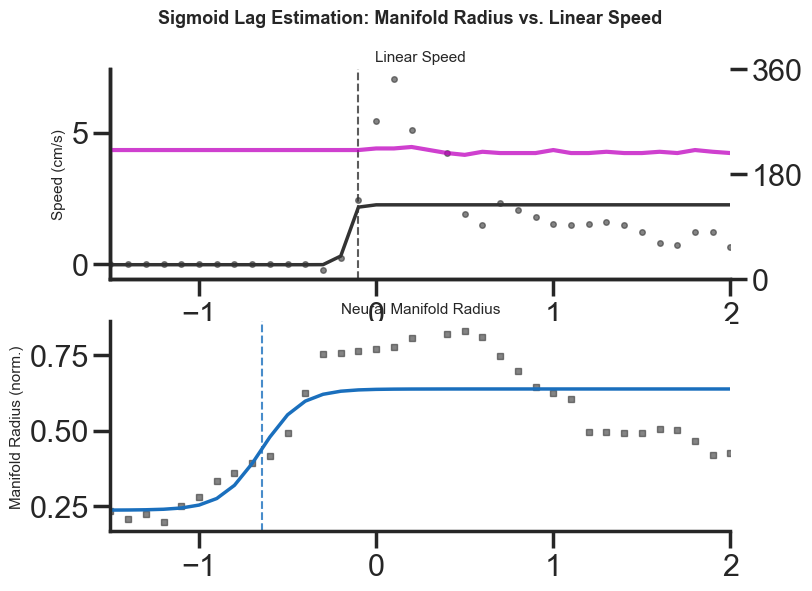

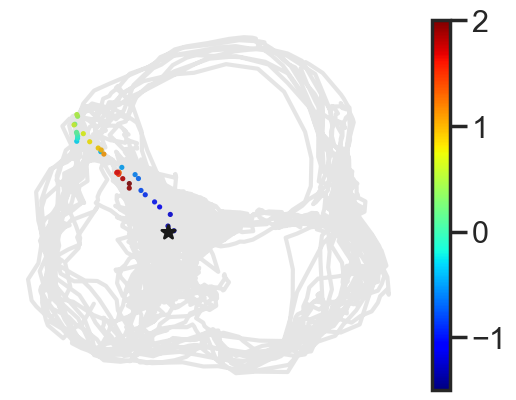

In [544]:
ls_lag = []
ls_df = []
time_idx = np.arange(35)
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1)
to_plot = True

for epid in df_stat2run.epoch_id.unique():
    
    if epid != '20220815_JA0181_darkHR1_3760':
        continue
        
    print (epid)
    tmp_stat2run = df_stat2run[df_stat2run.epoch_id == epid]
    speed = tmp_stat2run['epoch_speed'].values
    ep_yaw = tmp_stat2run['epoch_yaw'].values
    radius = tmp_stat2run['epoch_ring_rad'].values
    ep_emb_x = tmp_stat2run['epoch_emb_x'].values
    ep_emb_y = tmp_stat2run['epoch_emb_y'].values
    rec_id = tmp_stat2run['rec_id'][0]
    emb_x, emb_y = d_hr_emb[rec_id]['isomap'][:, 0], d_hr_emb[rec_id]['isomap'][:, 1]
    

    p0_speed  = [0.0,  10.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
    p0_radius = [-0.5, 1.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
    
    popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
    popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
    
    t0_speed  = popt_s[0] if popt_s is not None else np.nan
    t0_radius = popt_r[0] if popt_r is not None else np.nan
    
    # circstd was computed within 1s
    if abs(t0_speed) > 1 or abs(t0_radius) > 1:
        print(f't0 beyond limits of constant yaw')
        continue
        
    perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
    perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4

    try:
        stat2run_idx = np.where(fit_s > 2)[0][0]
        stat2run_t = t[stat2run_idx]
        base_fit_s = fit_s[:stat2run_idx].mean()
    except:
        print(f'bad fitting')
        continue
        
    lag = t0_radius - stat2run_t   # negative → radius leads speed

    if fit_s[:10].mean() > 2:
        print('base fit_s speed > 1 cm/s')
        continue
    is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
    is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

    if is_good_speed[0] & is_good_rad[0]:
        print(f'good epoch {is_good_speed} {is_good_rad}')
    else:
        print(f'bad epoch {is_good_speed} {is_good_rad}')
        continue

    
    print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
    print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
    print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
    
    if to_plot == True:
        fig, axes = plt.subplots(2, 1, figsize=(8, 6))
        fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                     fontsize=13, fontweight='bold', y=0.98)
                
        # --- Panel 1: Speed ---
        ax = axes[0]
        ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
        ax.plot(t, fit_s, '-', color='#333333', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
        ax.axvline(stat2run_t, color='#333333', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Speed (cm/s)', fontsize=11)
        # ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Linear Speed', fontsize=11)

        ax_2 = ax.twinx()
        ax_2.plot(t, ep_yaw, 'm', label = 'yaw', alpha = 0.75)
        ax_2.set_yticks([0, 180, 360])
     
        
        # ax.grid(True, alpha=0.3)
        
        # --- Panel 2: Radius ---
        ax = axes[1]
        ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
        ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
        ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
        # ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Neural Manifold Radius', fontsize=11)
        # ax.grid(True, alpha=0.3)
        
        # filepath = save_dir / f'line_{epid}_r-fit.pdf'
        # plt.savefig(filepath, transparent = True)
      
    

        # time.sleep(0.2)
        
        f, ax = plt.subplots()
        plt.scatter(ep_emb_x[:], ep_emb_y[:], alpha = 1, s = 3,  c = t, 
                    cmap = 'jet')
        plt.colorbar()
        plt.plot(emb_x[:], emb_y[:], c = 'gray', alpha = 0.2)
        plt.scatter(ep_emb_x[0], ep_emb_y[0], c = 'k', s = 100, marker = "*")
        plt.axis('off')
        
        # filepath = save_dir / f'scatter-hr_{epid}_vel_rad.pdf'
        # plt.savefig(filepath, transparent = True)
    
        plt.show()
        

    # break
#     tmp_df = pd.DataFrame({'rec_id': rec_id, 'epoch': epid, 'ep_speed': speed, 'lag_s':lag, 'ep_emb_x': ep_emb_x, 'ep_emb_y':ep_emb_y,
#                           'ep_yaw': ep_yaw, 'ep_radius': radius, 'time_s':t, 'speed_onset':stat2run_t, 'rad_onset':t0_radius, 'fit_s': fit_s, 'fit_r': fit_r,
#                           })
#     ls_df.append(tmp_df)
#     # break
# df_run_onset = pd.concat(ls_df)
# df_run_onset.head()

In [545]:
# pd.DataFrame({'ep_emb_x': ep_emb_x, 'ep_emb_y': ep_emb_y, 'speed': speed, 'fit_s': fit_s, 't':t, 
#               'radius': radius, 'fit_r': fit_r, 'ep_yaw': ep_yaw}).to_excel(filepath, index = True)

In [532]:
df_run_onset.epoch.unique().size

11

In [533]:
df_run_onset.rec_id.unique()

array(['20220302_JA0162_lightHR1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_darkHR1', '20220819_JA0178_darkHR1',
       '20220815_JA0181_darkHR1', '20220818_JA0181_darkHR1'], dtype=object)

In [534]:
lag_arr = df_run_onset.loc[0]['lag_s'].values
print(lag_arr)

[ 0.02912815 -0.43445954 -0.08927615 -0.54307123 -0.60360009 -0.75503257
 -0.07997578 -0.45303585 -0.85599253 -0.54728121 -0.26293517]


# of epochs 11
mean -0.41777563479441215 -0.8559925310759491 0.029128147044438266
sem 0.08634068607898707


(-1.5, 1.5)

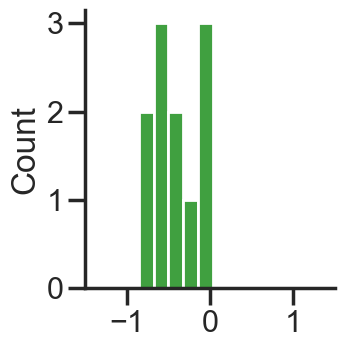

In [535]:
sns.displot(lag_arr, bins = 5, color = 'green', height=4, aspect = 1)
print('# of epochs', len(lag_arr))
print('mean', np.mean(lag_arr), lag_arr.min(), lag_arr.max())
print('sem', stats.sem(lag_arr))

plt.xlim(-1.5, 1.5)

# filepath = save_dir / 'dist_hr_lag-rad_vel.pdf'
# plt.savefig(filepath, transparent = True)

In [538]:
# pd.DataFrame(lag_arr).to_excel(filepath, index = True)

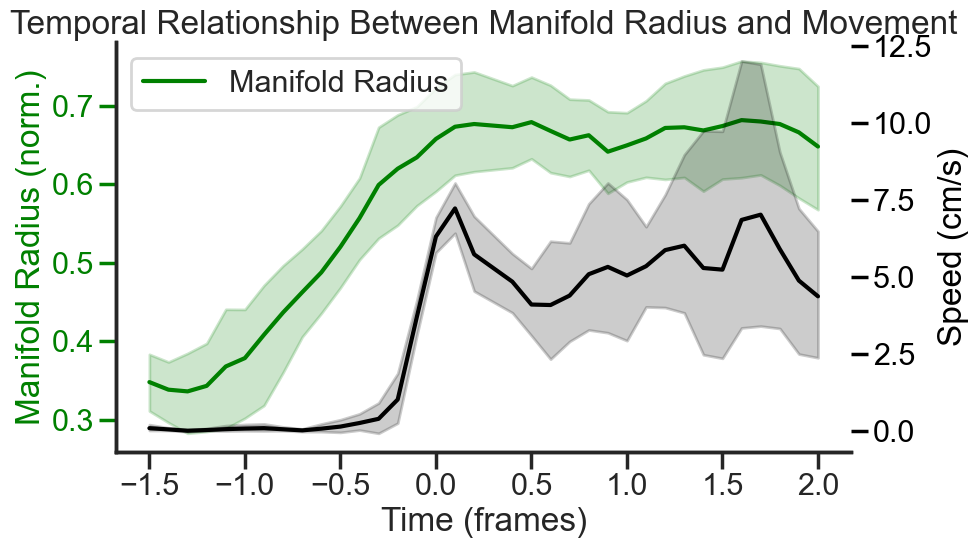

In [539]:
fig, ax1 = plt.subplots(figsize=(10, 6))
_inp = df_run_onset
# Plot radius data on primary axis
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_radius',
    ax=ax1,
    color='green',
    label='Manifold Radius'
)
ax1.set_xlabel('Time (frames)')
ax1.set_ylabel('Manifold Radius (norm.)', color='green')
ax1.tick_params(axis='y', colors='green')

# Add a secondary y-axis for speed
ax2 = ax1.twinx()
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_speed',
    ax=ax2,
    color='k',
    # label='Speed'
)
ax2.set_ylabel('Speed (cm/s)', color='k')
ax2.tick_params(axis='y', colors='k')

# Add vertical line at t=0 (movement onset)
# ax1.axvline(x=15, color='black', linestyle='--', label='Movement Onset')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Temporal Relationship Between Manifold Radius and Movement')
plt.tight_layout()

# filepath = save_dir / 'line-hr_vel_rad.pdf'
# plt.savefig(filepath, transparent = True)

In [540]:
# import os
# print(f"Current directory: {os.getcwd()}")
# print(f"Writeable: {os.access(os.getcwd(), os.W_OK)}")

Current directory: H:\My Drive\SNL @NU\Papers\ADN HD VR-Hfree paper\Data analysis
Writeable: True


In [541]:
# filepath = save_dir / f'out.xlsx'
# _inp.to_excel(filepath, index = True)


0.61 -0.4


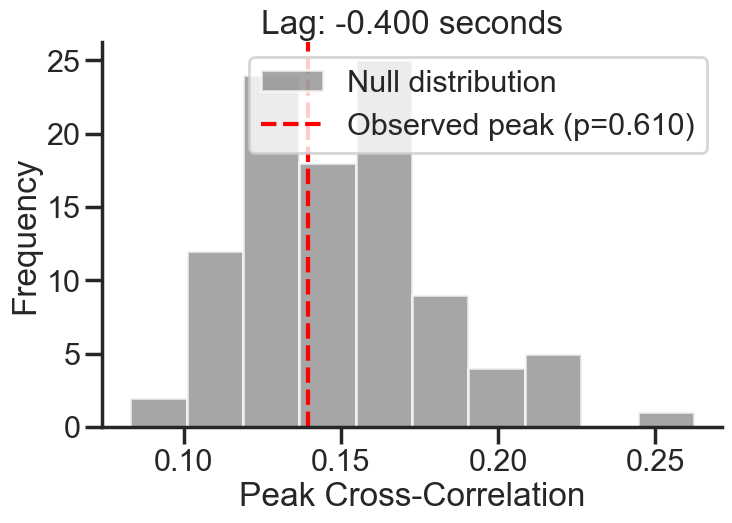

In [113]:
a = df_run_onset.groupby([ 'time_s'])['ep_speed'].mean()
b = df_run_onset.groupby([ 'time_s'])['ep_radius'].mean()
speed_diff = np.diff(a.values)
radius_diff = np.diff(b.values)
is_significant, p_value, lag_seconds = test_xcorr_significance(radius_diff, speed_diff, n_shuffles=100, fs=10, to_plot = True)
print(p_value, lag_seconds)
# plt.savefig(f'xcorr-vr_meanvel_rad.pdf', transparent = True)